  ***Projet Deep Learning***

------------------------------------------------------------------------------------------------------------------------------

**Objectif** :
Le but est de classifier les tumeurs cérébrales à partir d'images IRM (Imagerie par Résonance Magnétique), et éventuellement de générer un masque de segmentation pour localiser la tumeur. Le projet se concentre surtout sur la classification en 4 classes.

-----------------------------------------------------------------------------

**Les 4 classes dans ma dataset :**
1. **Glioma Tumor** (ورم الدبق)
Origine : Les gliomes se développent à partir des cellules gliales (الخلایا الدبقیة), qui soutiennent les neurones.

Types courants : astrocytomes, glioblastomes.

Caractéristiques IRM : masse infiltrante, souvent mal définie, qui peut se propager au tissu cérébral voisin.

Gravité : peut être agressive (surtout glioblastome), nécessite traitement rapide.

2. **Meningioma Tumor** (ورم السحايا)
Origine : Provient des méninges (الأغشیة التي تحیط بالدماغ والحبل الشوكي).

Caractéristiques IRM : souvent bien délimitée, à croissance lente.

Gravité : généralement bénigne mais peut exercer une pression sur le cerveau selon la taille et la localisation.

3. **Pituitary Tumor** (ورم الغدة النخامية)
Origine : Glánde pituitaire (الغدة النخامية), qui régule plusieurs hormones.

Caractéristiques IRM : visible au centre du cerveau (à la base), souvent petite taille.

Effets secondaires : peut dérégler les hormones, affecter la vision si compression du nerf optique.

4. **No Tumor** : Images cérébrales normales sans anomalie.


In [1]:
import numpy as np 
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import seaborn as sns
import copy
import time
import cv2


Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


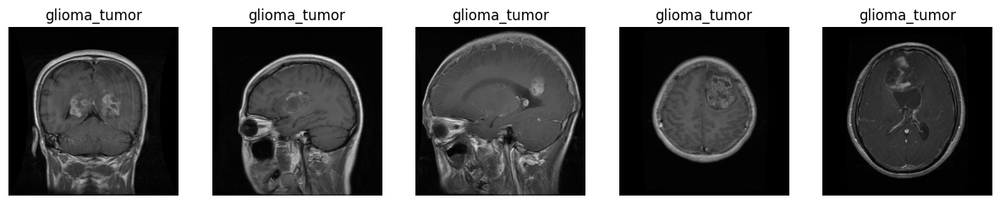

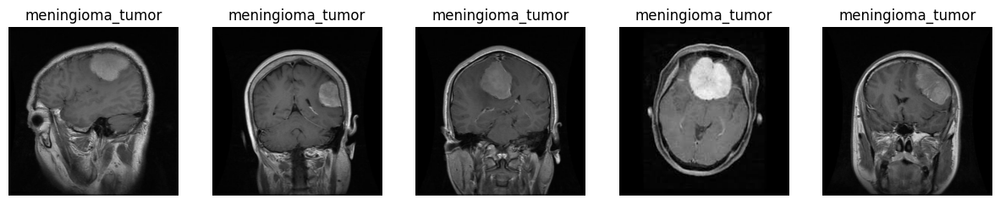

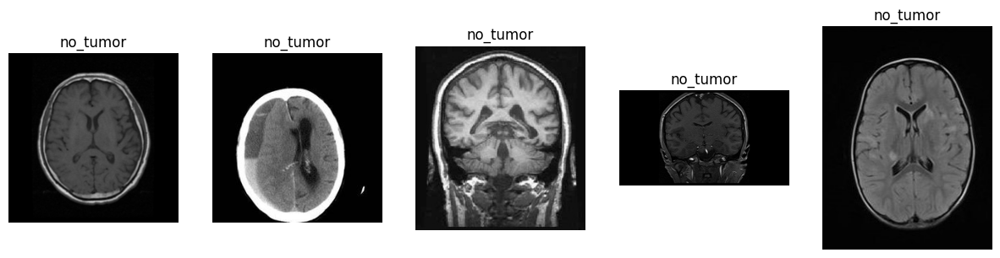

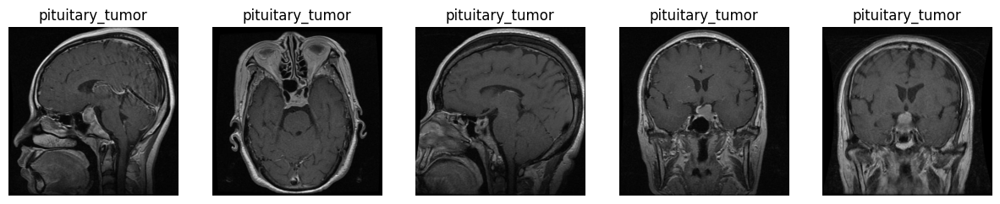

In [2]:
import os
import matplotlib.pyplot as plt
import random
from PIL import Image

# Paths
train_dir = 'Brain-Tumor-Classification-DataSet-master\Training' 
test_dir = 'Brain-Tumor-Classification-DataSet-master\Testing'    
classes = os.listdir(train_dir)
print(f"Classes: {classes}")

def show_samples(base_path, class_name, n=5):
    path = os.path.join(base_path, class_name)
    images = random.sample(os.listdir(path), n)
    plt.figure(figsize=(15, 5))
    for idx, img_name in enumerate(images):
        img_path = os.path.join(path, img_name)
        img = Image.open(img_path)
        plt.subplot(1, n, idx+1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis('off')
    plt.show()

for cls in classes:
    show_samples(train_dir, cls, n=5)


**Données**

    Le dataset est divisé en Training et Testing, chaque dossier contenant les 4 classes.

    Un script permet d'afficher aléatoirement des exemples d’IRM pour chaque classe.

    Un comptage du nombre d’images par classe est effectué pour mieux comprendre la distribution.

Training Set:
  glioma_tumor: 826 images
  meningioma_tumor: 822 images
  no_tumor: 395 images
  pituitary_tumor: 827 images

Testing Set:
  glioma_tumor: 100 images
  meningioma_tumor: 115 images
  no_tumor: 105 images
  pituitary_tumor: 74 images


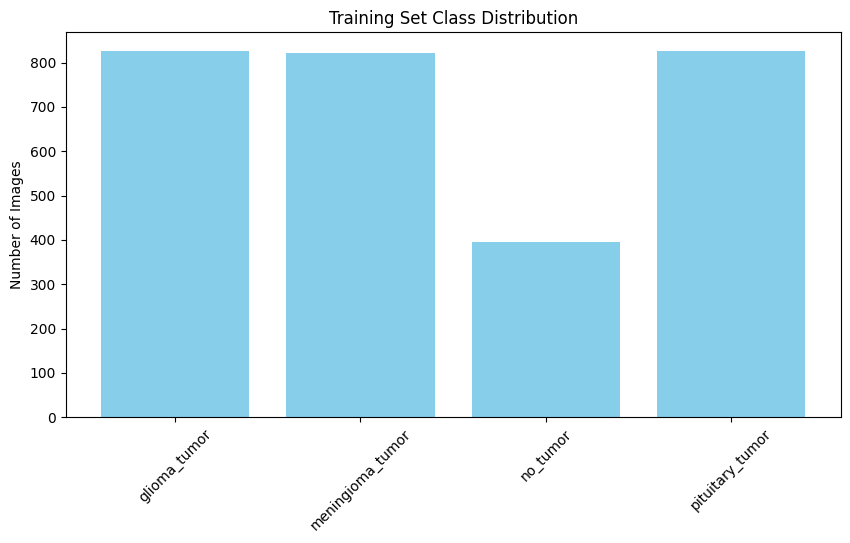

In [3]:
import os
import matplotlib.pyplot as plt

def count_images(directory):
    class_counts = {}
    for cls in os.listdir(directory):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            class_counts[cls] = len(os.listdir(cls_path))
    return class_counts

train_counts = count_images(train_dir)
test_counts = count_images(test_dir)

print("Training Set:")
for k, v in train_counts.items():
    print(f"  {k}: {v} images")

print("\nTesting Set:")
for k, v in test_counts.items():
    print(f"  {k}: {v} images")

# Plotting
plt.figure(figsize=(10,5))
plt.bar(train_counts.keys(), train_counts.values(), color='skyblue')
plt.title("Training Set Class Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()


Le jeu d'entraînement contient un total de 2870 images, avec une répartition relativement équilibrée entre les trois types de tumeurs (environ 826 images chacune), tandis que la classe "no tumor" est nettement sous-représentée avec seulement 395 images, ce qui peut introduire un déséquilibre et biaiser l’apprentissage du modèle. Le jeu de test, composé de 394 images, suit une distribution similaire, bien que la classe "pituitary tumor" y soit légèrement moins représentée. Ce dataset, de taille raisonnable, est adapté à l’entraînement de modèles de deep learning, en particulier ceux pré-entraînés comme VGG ou ResNet. Toutefois, pour garantir des performances équilibrées entre les classes, il est recommandé d’utiliser des techniques comme l’augmentation de données, la pondération des classes ou encore le suréchantillonnage de la classe "no tumor". 

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)


Using device: cuda


In [5]:
train_dir = "Brain-Tumor-Classification-DataSet-master\Training"
test_dir = "Brain-Tumor-Classification-DataSet-master\Testing"

transform = transforms.Compose([
    transforms.Resize((224, 224)),  
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])  
])

train_dataset = datasets.ImageFolder(train_dir, transform=transform)
test_dataset = datasets.ImageFolder(test_dir, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

class_names = train_dataset.classes
print("Classes:", class_names)


Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


***Modèle utilisé : ResNet-18***

    Utilisation de ResNet-18 pré-entraîné sur ImageNet.

    Les couches convolutionnelles sont gelées (requires_grad=False) pour ne pas les réentraîner.

    Seule la dernière couche (fully connected) est remplacée pour sortir 4 classes.

    Entraînement avec :

        CrossEntropyLoss pour la classification multiclasse.

        Adam comme optimiseur.

        Entraînement pendant 5 époques (epochs=5).

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

model = models.resnet18(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 4) 

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total
    
    print(f"Epoch {epoch+1}/{epochs}, Loss: {train_loss:.4f}, Accuracy: {train_acc:.2f}%")

print(" Training Finished")


Device: cuda


C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\bough/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████

Epoch 1/5, Loss: 0.8992, Accuracy: 65.78%
Epoch 2/5, Loss: 0.5916, Accuracy: 78.89%
Epoch 3/5, Loss: 0.5103, Accuracy: 81.43%
Epoch 4/5, Loss: 0.4751, Accuracy: 82.44%
Epoch 5/5, Loss: 0.4469, Accuracy: 83.90%
 Training Finished


L'entraînement de ResNet18 montre une amélioration claire en seulement 5 époques, avec une précision passant de 65.78 % à 83.90 % et une perte diminuant de 0.8992 à 0.4469. Cela indique que le modèle apprend efficacement et converge bien, même sur un nombre d'époques limité, ce qui est prometteur pour ce type de classification.


Amélioration du pipeline avec augmentation de données

    Application de data augmentation pour le jeu d'entraînement :

        RandomHorizontalFlip

        RandomRotation

        RandomAffine

        ColorJitter

    Objectif : mieux généraliser et éviter le surapprentissage.

In [6]:
# Paths
train_dir = 'Brain-Tumor-Classification-DataSet-master/Training'
test_dir = 'Brain-Tumor-Classification-DataSet-master/Testing'

# Transforms
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=15, translate=(0.1,0.1), scale=(0.9,1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transforms)

# DataLoaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# Classes
class_names = train_dataset.classes
print(class_names)


['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


In [7]:
model = models.resnet18(pretrained=True)

# Replace the last FC layer
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(class_names))

model = model.to(device)


C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Nouveau modèle ResNet-18 avec :

    Fine-tuning complet du modèle (non gelé)

    Optimiseur Adam avec lr=1e-4

    Scheduler ReduceLROnPlateau : réduit le learning rate si la validation stagne

    Early stopping avec patience de 5 époques

    Sauvegarde du meilleur modèle

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, verbose=True)

# Early Stopping Params
patience = 5
best_val_loss = np.inf
early_stop_counter = 0

# Save best model path
best_model_wts = copy.deepcopy(model.state_dict())


C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [9]:
num_epochs = 30
train_losses, val_losses = [], []

for epoch in range(num_epochs):
    print(f'Epoch {epoch+1}/{num_epochs}')
    
    model.train()
    running_loss = 0.0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    # Validation
    model.eval()
    val_loss = 0.0
    preds, true_labels = [], []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            
            _, predictions = torch.max(outputs, 1)
            preds.extend(predictions.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())
    
    epoch_train_loss = running_loss / len(train_loader)
    epoch_val_loss = val_loss / len(test_loader)
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    
    acc = accuracy_score(true_labels, preds)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {acc:.4f}')
    
    scheduler.step(epoch_val_loss)
    
    # Early Stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_wts = copy.deepcopy(model.state_dict())
        early_stop_counter = 0
        torch.save(model.state_dict(), 'best_model.pth')
        print('Saving best model...')
    else:
        early_stop_counter += 1
        if early_stop_counter >= patience:
            print('Early stopping triggered')
            break

# Load best model weights
model.load_state_dict(best_model_wts)


Epoch 1/30
Train Loss: 0.4680 | Val Loss: 1.2955 | Val Acc: 0.6345
Saving best model...
Epoch 2/30
Train Loss: 0.1923 | Val Loss: 0.9381 | Val Acc: 0.7843
Saving best model...
Epoch 3/30
Train Loss: 0.1515 | Val Loss: 1.2250 | Val Acc: 0.6904
Epoch 4/30
Train Loss: 0.1147 | Val Loss: 1.3418 | Val Acc: 0.7157
Epoch 5/30
Train Loss: 0.0859 | Val Loss: 1.4499 | Val Acc: 0.7259
Epoch 6/30
Train Loss: 0.0476 | Val Loss: 1.1486 | Val Acc: 0.7614
Epoch 7/30
Train Loss: 0.0523 | Val Loss: 0.9839 | Val Acc: 0.7944
Early stopping triggered


<All keys matched successfully>

**Interprètation :**
Le modèle commence bien, avec une baisse rapide de la perte d’entraînement (de 0.4680 à 0.0523) et une augmentation de la précision en validation (jusqu’à 79.44 %). Les meilleures performances de validation sont atteintes à l’époque 7, mais dès l’époque 3, on remarque que la val_loss reste élevée et instable, alors que la train_loss continue à baisser.

Cela indique un surapprentissage (overfitting) : le modèle s’améliore fortement sur les données d’entraînement, mais pas sur les données de validation. L’early stopping interrompt l’entraînement pour éviter d’aggraver ce phénomène.

Final Test Accuracy: 0.7843


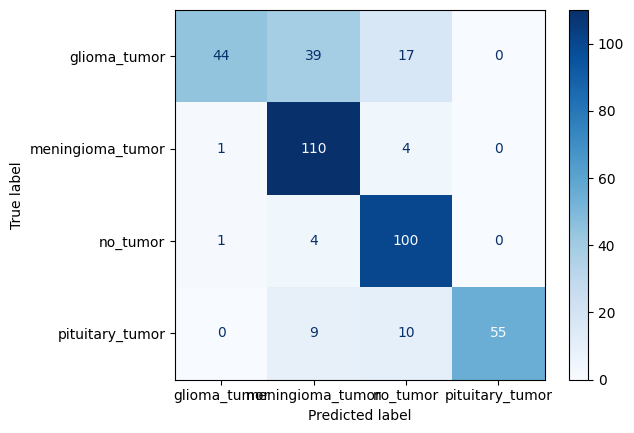

In [12]:
model.eval()
preds, true_labels = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predictions = torch.max(outputs, 1)
        preds.extend(predictions.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

acc = accuracy_score(true_labels, preds)
print(f'Final Test Accuracy: {acc:.4f}')

# Confusion Matrix
cm = confusion_matrix(true_labels, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues')
plt.show()


**Interprétation :**
Ce score reflète la capacité de généralisation du modèle.

Une précision de ~78 % est correcte pour une tâche de classification médicale comme celle des tumeurs cérébrales, mais elle laisse encore place à l’amélioration.

Cela confirme aussi que le modèle n’a pas complètement surappris, malgré les signes d’overfitting détectés pendant l'entraînement.

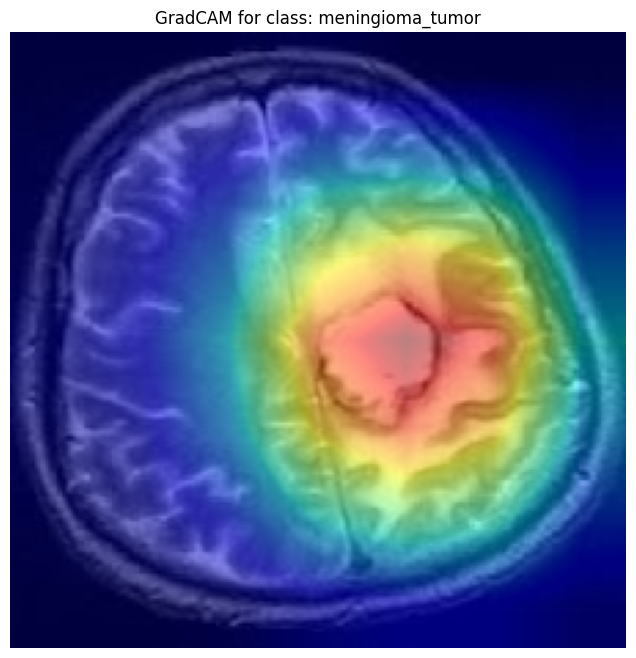

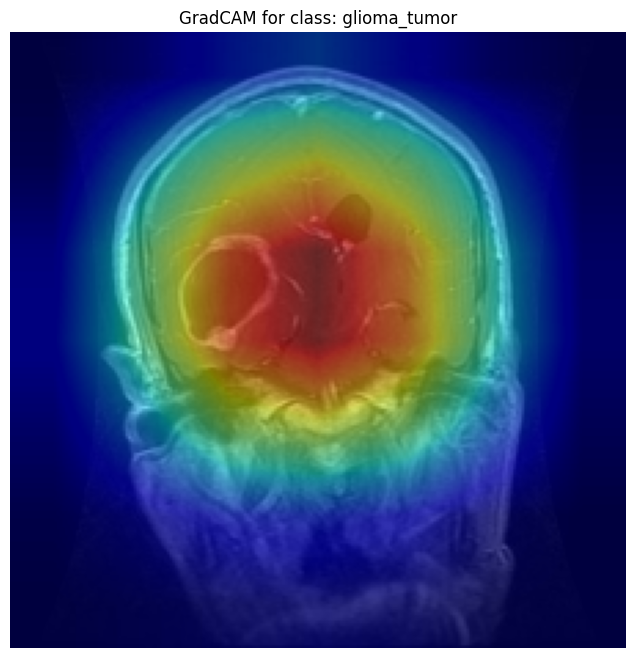

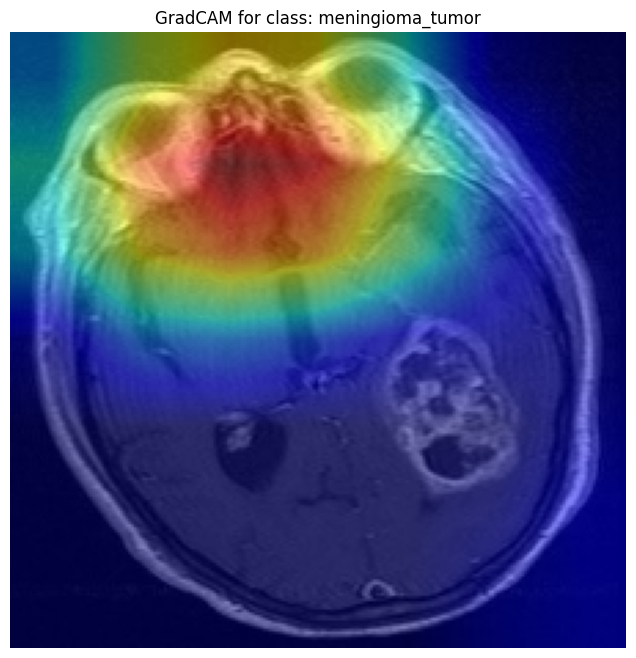

In [11]:
def visualize_gradcam(model, image_path, class_idx=None):
    model.eval()
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, (224,224))
    input_tensor = test_transforms(Image.fromarray(img_resized)).unsqueeze(0).to(device)
    
    # Hook the feature maps
    features_blobs = []

    def hook_feature(module, input, output):
        features_blobs.append(output.cpu().data.numpy())

    finalconv_name = 'layer4'
    model._modules.get(finalconv_name).register_forward_hook(hook_feature)

    # Forward
    output = model(input_tensor)
    if class_idx is None:
        class_idx = torch.argmax(output).item()

    # Get weight from the last FC layer
    params = list(model.parameters())
    weight_softmax = params[-2].cpu().data.numpy()

    # GradCAM calculation
    feature_maps = features_blobs[0][0]
    cam = np.zeros(feature_maps.shape[1:], dtype=np.float32)

    for i, w in enumerate(weight_softmax[class_idx]):
        cam += w * feature_maps[i, :, :]

    cam = np.maximum(cam, 0)
    cam = cv2.resize(cam, (224, 224))
    cam -= np.min(cam)
    cam /= np.max(cam)

    # Visualization
    plt.figure(figsize=(8,8))
    plt.imshow(img_resized)
    plt.imshow(cam, cmap='jet', alpha=0.5)
    plt.title(f'GradCAM for class: {class_names[class_idx]}')
    plt.axis('off')
    plt.show()

from PIL import Image
visualize_gradcam(model, "Brain-Tumor-Classification-DataSet-master/Testing/glioma_tumor/image(84).jpg")
visualize_gradcam(model, "Brain-Tumor-Classification-DataSet-master/Testing/glioma_tumor/image(69).jpg")
visualize_gradcam(model, "Brain-Tumor-Classification-DataSet-master/Testing/glioma_tumor/image(98).jpg")



***ConVNext***

In [13]:
import timm
from tqdm import tqdm

In [14]:
# 2. Data Augmentation + DataLoader
data_dir = 'Brain-Tumor-Classification-DataSet-master'

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(os.path.join(data_dir, 'Training'), transform=train_transform)
test_dataset = datasets.ImageFolder(os.path.join(data_dir, 'Testing'), transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

class_names = train_dataset.classes
print("Classes:", class_names)


Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


In [19]:
# 3. Model: ConvNeXt Transfer Learning
model.head = nn.Linear(model.head.in_features, 4)
model = timm.create_model('convnext_tiny', pretrained=True, num_classes=4, global_pool='avg')
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4)


In [20]:
# 4. EarlyStopping
class EarlyStopping:
    def __init__(self, patience=5, delta=0):
        self.patience = patience
        self.delta = delta
        self.best_loss = np.inf
        self.counter = 0
        self.early_stop = False
        self.best_model_wts = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.delta:
            self.best_loss = val_loss
            self.best_model_wts = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True


In [21]:
# 5. Training Loop
def train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs=30):
    early_stopping = EarlyStopping(patience=5)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}")

        model.train()
        running_loss, running_corrects = 0.0, 0

        for inputs, labels in tqdm(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = running_corrects.double() / len(train_loader.dataset)

        model.eval()
        val_loss, val_corrects = 0.0, 0

        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                _, preds = torch.max(outputs, 1)
                val_loss += loss.item() * inputs.size(0)
                val_corrects += torch.sum(preds == labels.data)

        val_loss = val_loss / len(test_loader.dataset)
        val_acc = val_corrects.double() / len(test_loader.dataset)

        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(epoch_acc.cpu().numpy())
        history['val_acc'].append(val_acc.cpu().numpy())

        print(f"Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

        early_stopping(val_loss, model)
        if early_stopping.early_stop:
            print("Early stopping triggered!")
            break

    print("Loading best model weights...")
    model.load_state_dict(early_stopping.best_model_wts)
    torch.save(model.state_dict(), 'convnext_best_model.pth')

    return model, history

model, history = train_model(model, train_loader, test_loader, criterion, optimizer)


Epoch 1/30


100%|██████████████████████████████████████████████████████████████████████████████████| 90/90 [38:08<00:00, 25.42s/it]


Train Loss: 1.3467 Acc: 0.3352 | Val Loss: 1.6601 Acc: 0.2386
Epoch 2/30


100%|██████████████████████████████████████████████████████████████████████████████████| 90/90 [36:36<00:00, 24.40s/it]


Train Loss: 0.6267 Acc: 0.7505 | Val Loss: 0.9226 Acc: 0.7107
Epoch 3/30


...

Train Loss: 0.0977 Acc: 0.9686 | Val Loss: 1.1105 Acc: 0.7843
Epoch 6/30


100%|██████████████████████████████████████████████████████████████████████████████████| 90/90 [36:47<00:00, 24.53s/it]


Train Loss: 0.0803 Acc: 0.9732 | Val Loss: 1.2965 Acc: 0.7792
Epoch 7/30


100%|██████████████████████████████████████████████████████████████████████████████████| 90/90 [36:45<00:00, 24.50s/it]


Train Loss: 0.0597 Acc: 0.9801 | Val Loss: 1.1619 Acc: 0.8122
Early stopping triggered!
Loading best model weights...


Début difficile : À l’époque 1, la précision est faible sur l’ensemble d’entraînement (33.5 %) et encore plus sur validation (23.8 %), ce qui est normal pour un début.

Progression rapide : Dès l’époque 2, le modèle apprend bien (train acc 75 %, val acc 71 %).

Surapprentissage progressif : Après l’époque 3, la précision sur le jeu d'entraînement continue à augmenter (jusqu’à 98 %), mais la val_acc stagne entre ~70–81 % et la val_loss augmente, ce qui est un signe d’overfitting.

Early stopping : Le processus s’est arrêté automatiquement à l’époque 7 pour éviter un surapprentissage excessif.

Meilleur modèle : Le modèle sauvegardé est celui de l’époque avec la meilleure val_acc (probablement époque 7, avec 81.2 %).

Accuracy: 0.7107


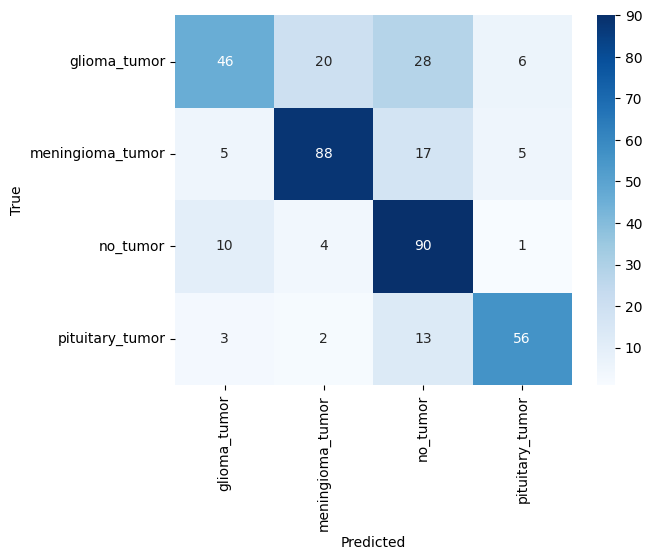

                  precision    recall  f1-score   support

    glioma_tumor       0.72      0.46      0.56       100
meningioma_tumor       0.77      0.77      0.77       115
        no_tumor       0.61      0.86      0.71       105
 pituitary_tumor       0.82      0.76      0.79        74

        accuracy                           0.71       394
       macro avg       0.73      0.71      0.71       394
    weighted avg       0.72      0.71      0.70       394



In [24]:
# 6. Evaluation: Accuracy + Confusion Matrix
from sklearn.metrics import confusion_matrix, classification_report
def evaluate_model(model, loader):
    model.eval()
    preds, targets = [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, pred = torch.max(outputs, 1)
            preds.extend(pred.cpu().numpy())
            targets.extend(labels.cpu().numpy())

    acc = np.mean(np.array(preds) == np.array(targets))
    print(f"Accuracy: {acc:.4f}")

    cm = confusion_matrix(targets, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    print(classification_report(targets, preds, target_names=class_names))

evaluate_model(model, test_loader)


Le modèle est assez performant pour les classes tumeurs méningiomes et tumeurs pituitaires, mais il a des difficultés avec les tumeurs gliomes, notamment en raison d'un faible rappel (46%) dans cette classe, et la classe sans tumeur nécessite un peu plus de précision. Cela pourrait indiquer que le modèle n'identifie pas suffisamment les cas de gliomes et est susceptible de sur-diagnostiquer les "pas de tumeur".

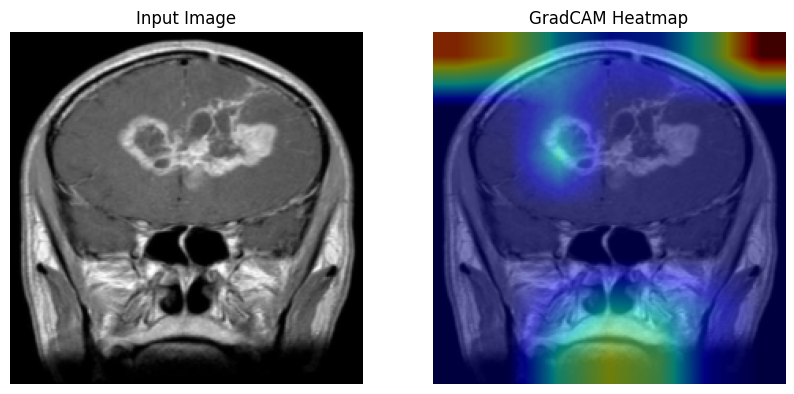

In [27]:
# GradCAM Visualization 
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_layers()

    def hook_layers(self):
        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0]

        def forward_hook(module, input, output):
            self.activations = output

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)  

    def generate(self, input_image, class_idx=None):
        self.model.eval()
        input_image = input_image.unsqueeze(0).to(device)
        output = self.model(input_image)

        if class_idx is None:
            class_idx = torch.argmax(output)

        self.model.zero_grad()
        output[0, class_idx].backward()

        gradients = self.gradients
        activations = self.activations

        weights = torch.mean(gradients, dim=[2, 3], keepdim=True)
        cam = torch.sum(weights * activations, dim=1).squeeze()

        cam = torch.clamp(cam, min=0).cpu().detach().numpy()
        cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))
        cam = cv2.resize(cam, (224, 224))

        return cam

def show_gradcam(model, loader, idx=0):
    # Get one batch
    inputs, labels = next(iter(loader))
    input_img = inputs[idx]
    label = labels[idx]

    # Adaptation pour ConvNeXt
    cam_extractor = GradCAM(model, model.stages[-1].blocks[-1])  

    # Générer la heatmap
    cam = cam_extractor.generate(input_img)

    # Préparer l'image pour affichage
    input_img = input_img.permute(1, 2, 0).cpu().numpy()
    input_img = (input_img - input_img.min()) / (input_img.max() - input_img.min())

    # Affichage
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title('Input Image')
    plt.imshow(input_img)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title('GradCAM Heatmap')
    plt.imshow(input_img)
    plt.imshow(cam, cmap='jet', alpha=0.5)
    plt.axis('off')

    plt.show()

# Utilisation
show_gradcam(model, test_loader)


***ResNet50 + Fine-tuning***

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\bough/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth
100%|██████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [04:42<00:00, 363kB/s]



Epoch 1/30
------------------------------
Train Loss: 0.7207, Val Loss: 1.2422

Epoch 2/30
------------------------------
Train Loss: 0.3033, Val Loss: 1.2292

Epoch 3/30
------------------------------
Train Loss: 0.2036, Val Loss: 0.9834

Epoch 4/30
------------------------------
Train Loss: 0.1704, Val Loss: 1.1793

Epoch 5/30
------------------------------
Train Loss: 0.1427, Val Loss: 1.2736

Epoch 6/30
------------------------------
Train Loss: 0.1345, Val Loss: 1.0145

Epoch 7/30
------------------------------
Train Loss: 0.0921, Val Loss: 1.1470

Epoch 8/30
------------------------------
Train Loss: 0.0913, Val Loss: 1.2419

Epoch 9/30
------------------------------
Train Loss: 0.0880, Val Loss: 1.1556

Epoch 10/30
------------------------------
Train Loss: 0.0857, Val Loss: 1.2257

Epoch 11/30
------------------------------
Train Loss: 0.0951, Val Loss: 1.1131

Epoch 12/30
------------------------------
Train Loss: 0.0848, Val Loss: 1.3403

Epoch 13/30
------------------------

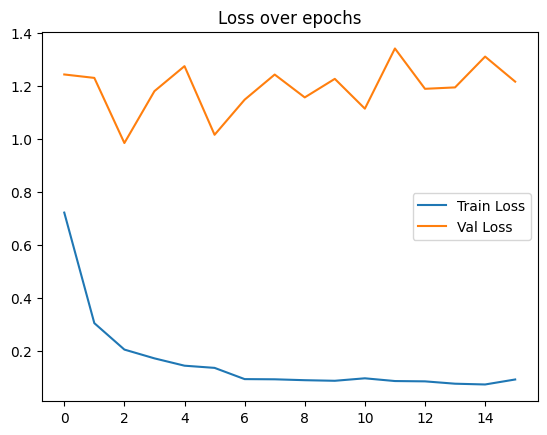

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torchvision import datasets, models, transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import cv2
import os
import copy
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('Brain-Tumor-Classification-DataSet-master/Training', transform=transform_train)
test_dataset = datasets.ImageFolder('Brain-Tumor-Classification-DataSet-master/Testing', transform=transform_test)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

class_names = train_dataset.classes
num_classes = len(class_names)


model = models.resnet50(weights='IMAGENET1K_V2')

# Freeze first layers
for name, param in model.named_parameters():
    if "layer4" not in name:  # fine-tune only layer4 and fc
        param.requires_grad = False

# Replace final layer
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)


criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)
scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

def train_model(model, criterion, optimizer, scheduler, num_epochs=20, patience=5):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    train_losses, val_losses = [], []
    early_stop_counter = 0

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 30)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = test_loader

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)

            if phase == 'train':
                train_losses.append(epoch_loss)
                scheduler.step()
            else:
                val_losses.append(epoch_loss)
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    early_stop_counter = 0
                else:
                    early_stop_counter += 1

        print(f'Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}')

        if early_stop_counter >= patience:
            print("\nEarly stopping triggered!")
            break

    print(f'\nBest Val Acc: {best_acc:.4f}')
    model.load_state_dict(best_model_wts)

    # Plot Loss Curves
    plt.figure()
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Val Loss')
    plt.legend()
    plt.title('Loss over epochs')
    plt.show()

    return model

model = train_model(model, criterion, optimizer, scheduler, num_epochs=30)

Test Accuracy: 0.7792


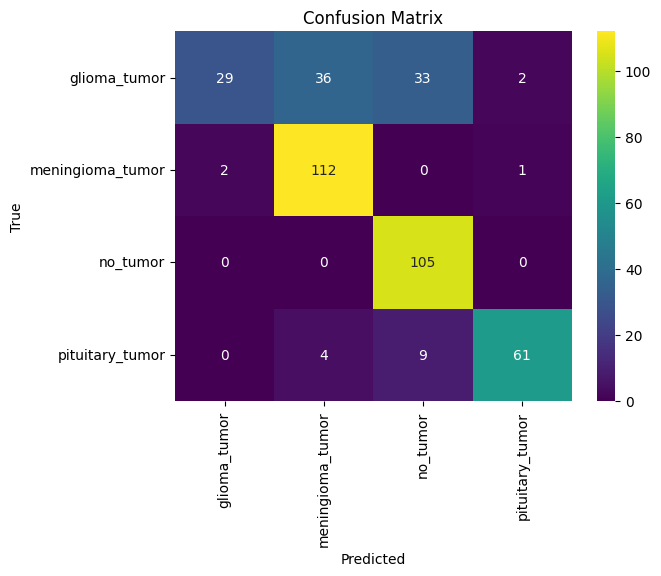

                  precision    recall  f1-score   support

    glioma_tumor       0.94      0.29      0.44       100
meningioma_tumor       0.74      0.97      0.84       115
        no_tumor       0.71      1.00      0.83       105
 pituitary_tumor       0.95      0.82      0.88        74

        accuracy                           0.78       394
       macro avg       0.83      0.77      0.75       394
    weighted avg       0.82      0.78      0.75       394



In [2]:
def evaluate_model(model, loader):
    model.eval()
    preds, targets = [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, pred = torch.max(outputs, 1)
            preds.extend(pred.cpu().numpy())
            targets.extend(labels.cpu().numpy())

    acc = np.mean(np.array(preds) == np.array(targets))
    print(f"Test Accuracy: {acc:.4f}")

    cm = confusion_matrix(targets, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()

    print(classification_report(targets, preds, target_names=class_names))

evaluate_model(model, test_loader)

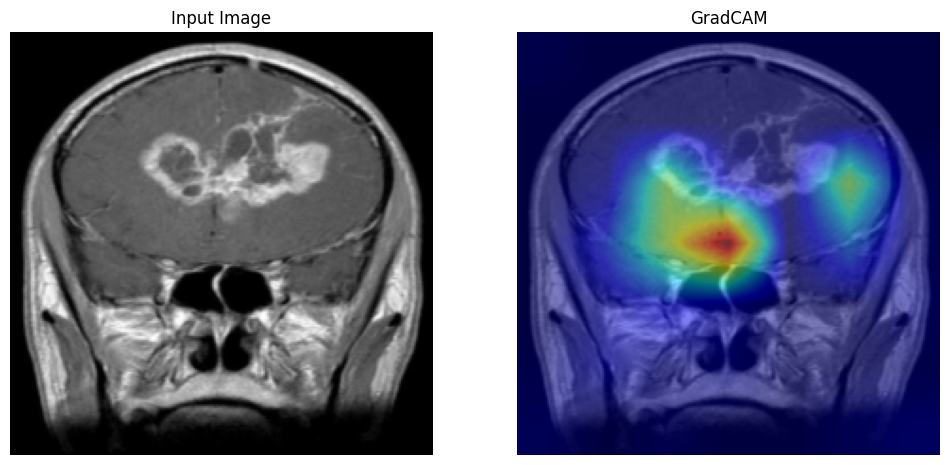

In [3]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_layers()

    def hook_layers(self):
        def forward_hook(module, input, output):
            self.activations = output
        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0]

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate(self, input_image, class_idx=None):
        self.model.eval()
        input_image = input_image.unsqueeze(0).to(device)
        output = self.model(input_image)

        if class_idx is None:
            class_idx = torch.argmax(output)

        self.model.zero_grad()
        output[0, class_idx].backward()

        gradients = self.gradients
        activations = self.activations

        weights = torch.mean(gradients, dim=[2, 3], keepdim=True)
        cam = torch.sum(weights * activations, dim=1).squeeze()
        cam = torch.clamp(cam, min=0).cpu().detach().numpy()
        cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))
        cam = cv2.resize(cam, (224, 224))

        return cam

def show_gradcam(model, loader, idx=0):
    inputs, labels = next(iter(loader))
    input_img = inputs[idx]
    label = labels[idx]

    cam_extractor = GradCAM(model, model.layer4[-1])
    cam = cam_extractor.generate(input_img)

    input_img = input_img.permute(1, 2, 0).cpu().numpy()
    input_img = np.clip(input_img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.title('Input Image')
    plt.imshow(input_img)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title('GradCAM')
    plt.imshow(input_img)
    plt.imshow(cam, cmap='jet', alpha=0.5)
    plt.axis('off')

    plt.show()

show_gradcam(model, test_loader)

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import cv2
from tqdm import tqdm
import os


In [5]:
# Transforms
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Dataset
data_dir = 'Brain-Tumor-Classification-DataSet-master'  
full_dataset = datasets.ImageFolder(root=data_dir, transform=train_transforms)

# Split
train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(full_dataset, [train_size, val_size, test_size])

train_dataset.dataset.transform = train_transforms
val_dataset.dataset.transform = test_transforms
test_dataset.dataset.transform = test_transforms

# Loaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

class_names = full_dataset.classes


In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet50(weights='IMAGENET1K_V1')
model.fc = nn.Linear(model.fc.in_features, 4)  
model = model.to(device)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to C:\Users\bough/.cache\torch\hub\checkpoints\resnet50-0676ba61.pth
100%|█████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [01:06<00:00, 1.53MB/s]


In [7]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

In [8]:
def train_model(model, train_loader, val_loader, epochs=25):
    best_acc = 0

    for epoch in range(epochs):
        print(f'\nEpoch {epoch+1}/{epochs}')
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for inputs, labels in tqdm(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_acc = correct / total
        val_acc = evaluate_accuracy(model, val_loader)

        print(f'Train Loss: {running_loss/len(train_loader):.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}')
        
        scheduler.step()

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_resnet50.pth')

def evaluate_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return correct / total


In [9]:
train_model(model, train_loader, val_loader, epochs=20)


Epoch 1/20


100%|██████████████████████████████████████████████████████████████████████████████████| 72/72 [00:30<00:00,  2.33it/s]


Train Loss: 0.5965 | Train Acc: 0.8586 | Val Acc: 0.8814

Epoch 2/20


100%|██████████████████████████████████████████████████████████████████████████████████| 72/72 [00:30<00:00,  2.36it/s]


Train Loss: 0.4998 | Train Acc: 0.8997 | Val Acc: 0.8814

Epoch 3/20


...

Train Loss: 0.4519 | Train Acc: 0.9256 | Val Acc: 0.8671

Epoch 19/20


100%|██████████████████████████████████████████████████████████████████████████████████| 72/72 [00:30<00:00,  2.37it/s]


Train Loss: 0.4497 | Train Acc: 0.9295 | Val Acc: 0.8793

Epoch 20/20


100%|██████████████████████████████████████████████████████████████████████████████████| 72/72 [00:30<00:00,  2.37it/s]


Train Loss: 0.4485 | Train Acc: 0.9352 | Val Acc: 0.8855


C:\Users\bough\AppData\Local\Temp\ipykernel_8324\2494442772.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_resnet50.pth'))



Test Accuracy: 0.8676


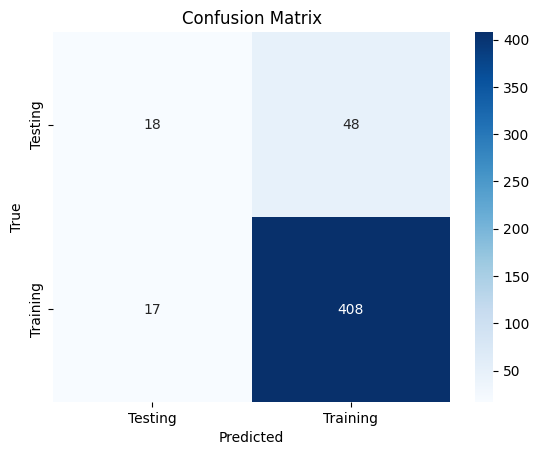


Classification Report:

              precision    recall  f1-score   support

     Testing       0.51      0.27      0.36        66
    Training       0.89      0.96      0.93       425

    accuracy                           0.87       491
   macro avg       0.70      0.62      0.64       491
weighted avg       0.84      0.87      0.85       491



In [10]:
# Charger le meilleur modèle
model.load_state_dict(torch.load('best_resnet50.pth'))

def test_model(model, loader):
    model.eval()
    preds, true_labels = [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, pred = torch.max(outputs, 1)
            preds.extend(pred.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())

    acc = np.mean(np.array(preds) == np.array(true_labels))
    print(f'\nTest Accuracy: {acc:.4f}')
    
    cm = confusion_matrix(true_labels, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()

    print('\nClassification Report:\n')
    print(classification_report(true_labels, preds, target_names=class_names))

test_model(model, test_loader)


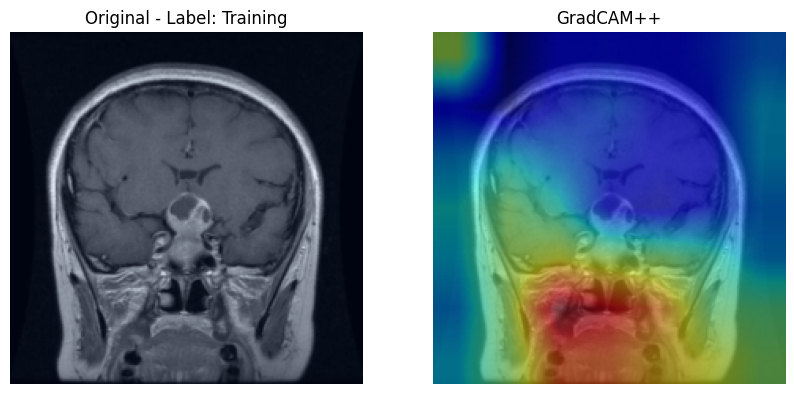

In [11]:
class GradCAMPlusPlus:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_layers()

    def hook_layers(self):
        def forward_hook(module, input, output):
            self.activations = output
        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0]
        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate(self, input_image, class_idx=None):
        self.model.eval()
        input_image = input_image.unsqueeze(0).to(device)
        output = self.model(input_image)

        if class_idx is None:
            class_idx = torch.argmax(output)

        self.model.zero_grad()
        output[0, class_idx].backward()

        gradients = self.gradients
        activations = self.activations

        weights = torch.mean(gradients, dim=[2, 3], keepdim=True)
        cam = torch.sum(weights * activations, dim=1).squeeze()

        cam = torch.clamp(cam, min=0).cpu().detach().numpy()
        cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))
        cam = cv2.resize(cam, (224, 224))

        return cam

def visualize_gradcam(model, loader, idx=0):
    inputs, labels = next(iter(loader))
    input_img = inputs[idx]
    label = labels[idx]

    gradcam = GradCAMPlusPlus(model, model.layer4[-1])
    cam = gradcam.generate(input_img)

    input_img_vis = input_img.permute(1, 2, 0).cpu().numpy()
    input_img_vis = (input_img_vis - input_img_vis.min()) / (input_img_vis.max() - input_img_vis.min())

    plt.figure(figsize=(10,5))
    plt.subplot(1, 2, 1)
    plt.title(f"Original - Label: {class_names[label.item()]}")
    plt.imshow(input_img_vis)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("GradCAM++")
    plt.imshow(input_img_vis)
    plt.imshow(cam, cmap='jet', alpha=0.5)
    plt.axis('off')
    plt.show()

visualize_gradcam(model, test_loader, idx=0)


***Efficientnet_b0***

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import timm
import cv2
import os


In [13]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)


cuda


In [14]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('Brain-Tumor-Classification-DataSet-master/Training', transform=transform_train)
test_dataset = datasets.ImageFolder('Brain-Tumor-Classification-DataSet-master/Testing', transform=transform_test)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

class_names = train_dataset.classes


In [15]:
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=len(class_names))
model = model.to(device)


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\bough\.cache\huggingface\hub\models--timm--efficientnet_b0.ra_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [16]:
# Handle imbalance
class_counts = np.bincount(train_dataset.targets)
class_weights = 1. / class_counts
weights = torch.tensor(class_weights, dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)

optimizer = optim.Adam(model.parameters(), lr=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=10)


In [17]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0


In [22]:
def train_model(model, train_loader, test_loader, epochs=30):
    early_stopping = EarlyStopping(patience=5)
    best_acc = 0

    for epoch in range(epochs):
        model.train()
        running_loss, running_corrects = 0.0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, preds = torch.max(outputs, 1)
            running_loss += loss.item()
            running_corrects += torch.sum(preds == labels.data)

        scheduler.step()

        epoch_loss = running_loss / len(train_loader)
        epoch_acc = running_corrects.double() / len(train_loader.dataset)

        print(f"Epoch {epoch+1}/{epochs} - Loss: {epoch_loss:.4f} - Train Acc: {epoch_acc:.4f}")

        val_acc = evaluate_model(model, test_loader)

        early_stopping(val_acc)
        if early_stopping.early_stop:
            print("Early stopping")
            break

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_modelEff.pth')

    print("Training complete. Best Test Acc: {:.4f}".format(best_acc))


In [23]:
def evaluate_model(model, loader):
    model.eval()
    preds, targets = [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, pred = torch.max(outputs, 1)
            preds.extend(pred.cpu().numpy())
            targets.extend(labels.cpu().numpy())

    acc = np.mean(np.array(preds) == np.array(targets))
    print(f"Test Accuracy: {acc:.4f}")

    cm = confusion_matrix(targets, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    print("\nClassification Report:\n")
    print(classification_report(targets, preds, target_names=class_names))

    return acc


In [24]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook()

    def hook(self):
        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0]

        def forward_hook(module, input, output):
            self.activations = output

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate(self, input_image, class_idx=None):
        self.model.eval()
        input_image = input_image.unsqueeze(0).to(device)
        output = self.model(input_image)

        if class_idx is None:
            class_idx = torch.argmax(output)

        self.model.zero_grad()
        output[0, class_idx].backward()

        gradients = self.gradients
        activations = self.activations

        weights = torch.mean(gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * activations, dim=1).squeeze()

        cam = torch.clamp(cam, min=0).cpu().detach().numpy()
        cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))
        cam = cv2.resize(cam, (224, 224))

        return cam

def show_gradcam(model, loader, idx=0):
    inputs, labels = next(iter(loader))
    input_img = inputs[idx]
    label = labels[idx]

    target_layer = model.conv_head  # EfficientNet specific
    cam_extractor = GradCAM(model, target_layer)
    cam = cam_extractor.generate(input_img)

    input_img = input_img.permute(1, 2, 0).cpu().numpy()
    input_img = (input_img - input_img.min()) / (input_img.max() - input_img.min())

    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    plt.title('Original')
    plt.imshow(input_img)
    plt.axis('off')

    plt.subplot(1,2,2)
    plt.title('GradCAM')
    plt.imshow(input_img)
    plt.imshow(cam, cmap='jet', alpha=0.5)
    plt.axis('off')
    plt.show()


Epoch 1/30 - Loss: 0.6007 - Train Acc: 0.8220
Test Accuracy: 0.5812


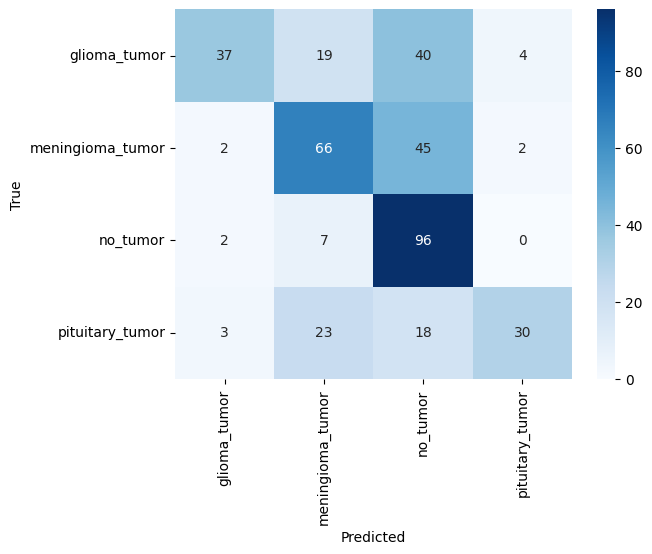


Classification Report:

                  precision    recall  f1-score   support

    glioma_tumor       0.84      0.37      0.51       100
meningioma_tumor       0.57      0.57      0.57       115
        no_tumor       0.48      0.91      0.63       105
 pituitary_tumor       0.83      0.41      0.55        74

        accuracy                           0.58       394
       macro avg       0.68      0.57      0.57       394
    weighted avg       0.67      0.58      0.57       394

Epoch 2/30 - Loss: 0.3657 - Train Acc: 0.8718
Test Accuracy: 0.6675


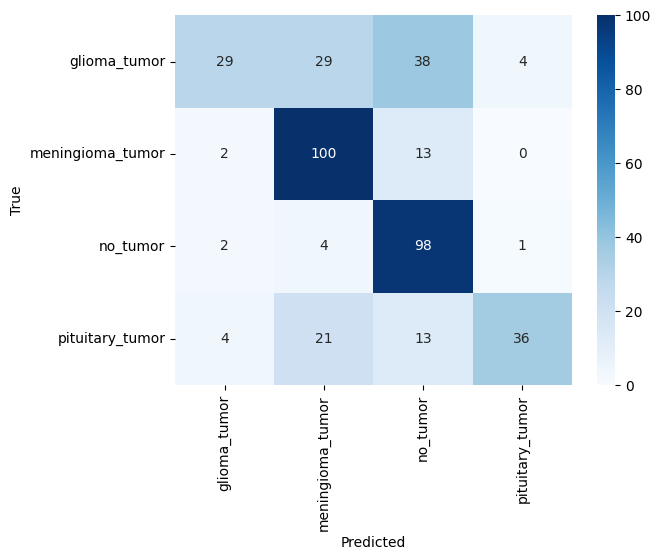


Classification Report:

                  precision    recall  f1-score   support

    glioma_tumor       0.78      0.29      0.42       100
meningioma_tumor       0.65      0.87      0.74       115
        no_tumor       0.60      0.93      0.73       105
 pituitary_tumor       0.88      0.49      0.63        74

        accuracy                           0.67       394
       macro avg       0.73      0.64      0.63       394
    weighted avg       0.71      0.67      0.64       394

Epoch 3/30 - Loss: 0.2203 - Train Acc: 0.9206
Test Accuracy: 0.7157


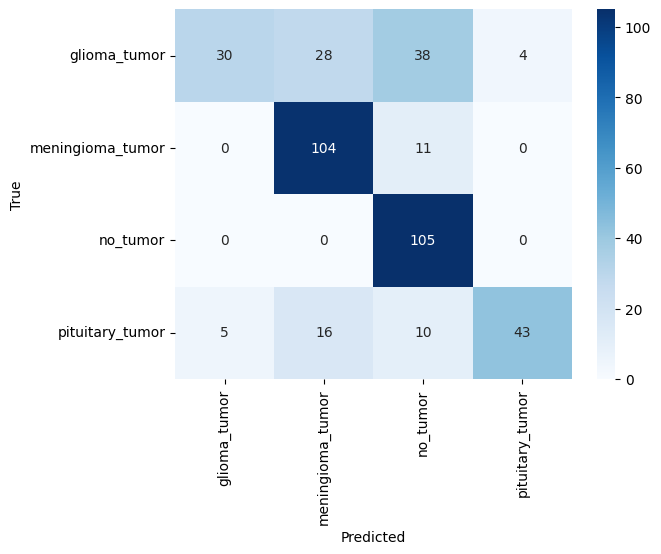


Classification Report:

                  precision    recall  f1-score   support

    glioma_tumor       0.86      0.30      0.44       100
meningioma_tumor       0.70      0.90      0.79       115
        no_tumor       0.64      1.00      0.78       105
 pituitary_tumor       0.91      0.58      0.71        74

        accuracy                           0.72       394
       macro avg       0.78      0.70      0.68       394
    weighted avg       0.77      0.72      0.69       394

Epoch 4/30 - Loss: 0.1577 - Train Acc: 0.9373
Test Accuracy: 0.7360


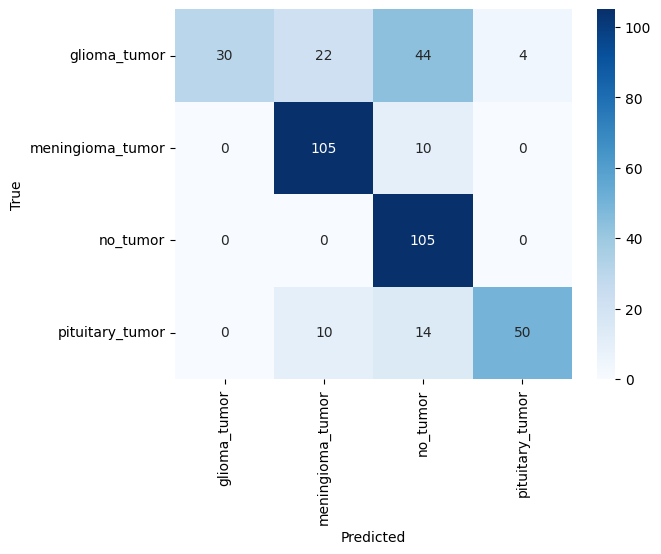


Classification Report:

                  precision    recall  f1-score   support

    glioma_tumor       1.00      0.30      0.46       100
meningioma_tumor       0.77      0.91      0.83       115
        no_tumor       0.61      1.00      0.76       105
 pituitary_tumor       0.93      0.68      0.78        74

        accuracy                           0.74       394
       macro avg       0.82      0.72      0.71       394
    weighted avg       0.81      0.74      0.71       394

Epoch 5/30 - Loss: 0.1148 - Train Acc: 0.9578
Test Accuracy: 0.7614


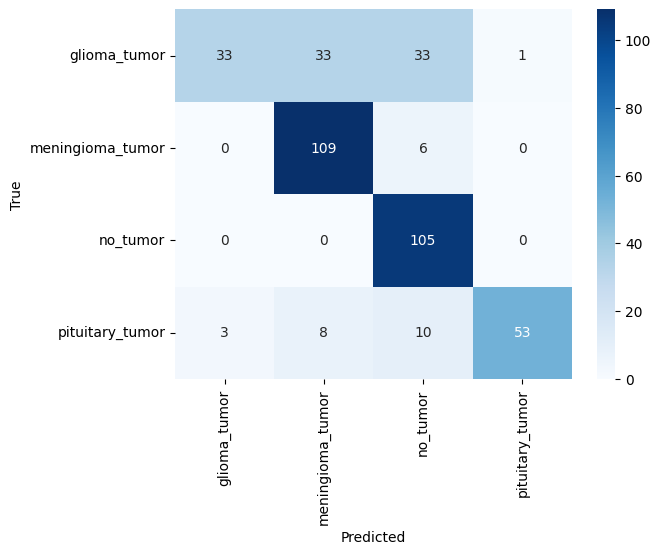


Classification Report:

                  precision    recall  f1-score   support

    glioma_tumor       0.92      0.33      0.49       100
meningioma_tumor       0.73      0.95      0.82       115
        no_tumor       0.68      1.00      0.81       105
 pituitary_tumor       0.98      0.72      0.83        74

        accuracy                           0.76       394
       macro avg       0.83      0.75      0.74       394
    weighted avg       0.81      0.76      0.73       394

Epoch 6/30 - Loss: 0.0969 - Train Acc: 0.9603
Test Accuracy: 0.7589


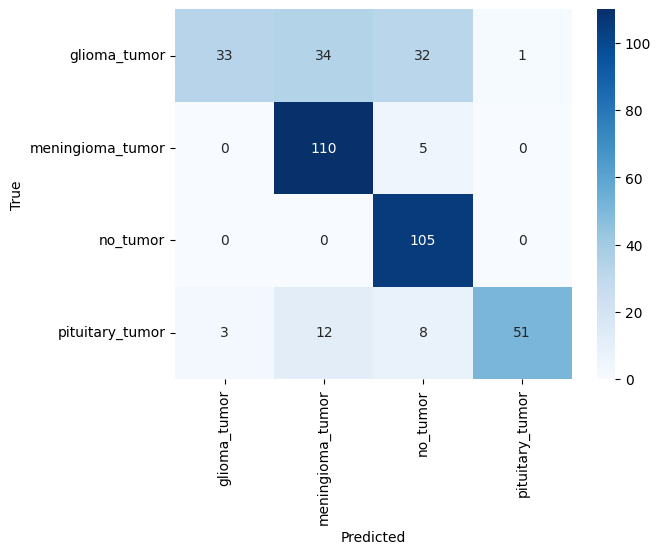


Classification Report:

                  precision    recall  f1-score   support

    glioma_tumor       0.92      0.33      0.49       100
meningioma_tumor       0.71      0.96      0.81       115
        no_tumor       0.70      1.00      0.82       105
 pituitary_tumor       0.98      0.69      0.81        74

        accuracy                           0.76       394
       macro avg       0.83      0.74      0.73       394
    weighted avg       0.81      0.76      0.73       394

Early stopping
Training complete. Best Test Acc: 0.7614


C:\Users\bough\AppData\Local\Temp\ipykernel_8324\203688048.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_modelEff.pth'))


Test Accuracy: 0.7614


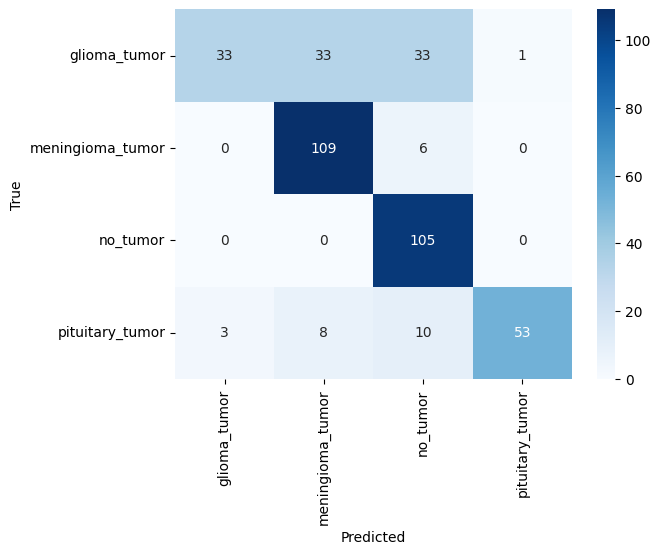


Classification Report:

                  precision    recall  f1-score   support

    glioma_tumor       0.92      0.33      0.49       100
meningioma_tumor       0.73      0.95      0.82       115
        no_tumor       0.68      1.00      0.81       105
 pituitary_tumor       0.98      0.72      0.83        74

        accuracy                           0.76       394
       macro avg       0.83      0.75      0.74       394
    weighted avg       0.81      0.76      0.73       394



C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


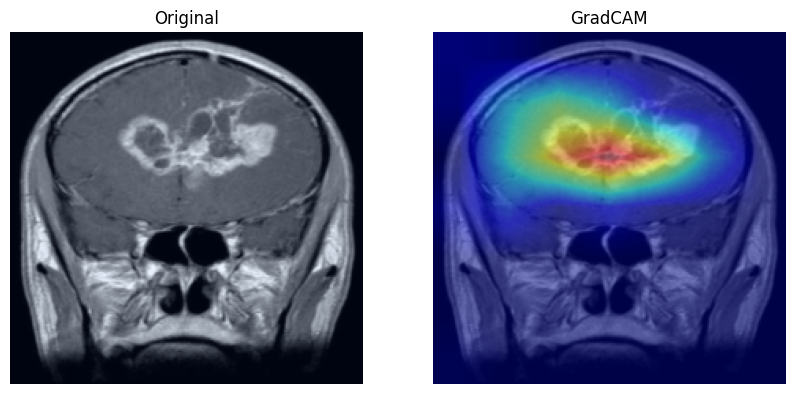

In [25]:
# Train
train_model(model, train_loader, test_loader, epochs=30)

# Load best model
model.load_state_dict(torch.load('best_modelEff.pth'))

# Evaluate final model
evaluate_model(model, test_loader)

# Show GradCAM
show_gradcam(model, test_loader)


***Swin Transformer***

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np
import os
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[INFO] Using device: {device}")

# --- Data Augmentation ---
train_transform = A.Compose([
    A.RandomRotate90(),
    A.HorizontalFlip(),
    A.VerticalFlip(),
    A.RandomBrightnessContrast(),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=20),
    A.Resize(224, 224),
    A.Normalize(),  # normalize to [0,1]
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(),
    ToTensorV2()
])

class BrainTumorDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.dataset = ImageFolder(root=root_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img_path, label = self.dataset.imgs[idx]
        image = plt.imread(img_path)

        if image.ndim == 2:  # Grayscale -> RGB
            image = np.stack([image]*3, axis=-1)

        image = image.astype(np.float32)

        if self.transform:
            image = self.transform(image=image)['image']

        return image, label

train_dir = 'Brain-Tumor-Classification-DataSet-master/Training'
val_dir = 'Brain-Tumor-Classification-DataSet-master/Testing'

train_dataset = BrainTumorDataset(train_dir, transform=train_transform)
val_dataset = BrainTumorDataset(val_dir, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# --- Load Pretrained Swin Transformer Model ---
model = timm.create_model('swin_tiny_patch4_window7_224', pretrained=True, num_classes=4)
model.to(device)

# --- Loss and Optimizer ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

# --- Training Parameters ---
num_epochs = 30
best_val_acc = 0

# --- Early Stopping Parameters ---
patience = 5
patience_counter = 0

# --- Training and Validation ---
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    scheduler.step()

    # --- Validation ---
    model.eval()
    correct = 0
    total = 0
    preds = []
    gts = []

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            preds.extend(predicted.cpu().numpy())
            gts.extend(labels.cpu().numpy())

    val_acc = 100 * correct / total
    print(f'Epoch [{epoch+1}/{num_epochs}] - Loss: {train_loss/len(train_loader):.4f} - Val Accuracy: {val_acc:.2f}%')

    # --- Check for Improvement ---
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_swin_transformer.pth')
        patience_counter = 0
        print("[INFO] Validation improved, model saved.")
    else:
        patience_counter += 1
        print(f"[INFO] No improvement. Patience: {patience_counter}/{patience}")

    # --- Early Stopping ---
    if patience_counter >= patience:
        print("[INFO] Early stopping triggered.")
        break

print("\n[INFO] Training Completed!")
print(classification_report(gts, preds))


C:\Users\bough\AppData\Roaming\Python\Python310\site-packages\albumentations\__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.6' (you have '2.0.5'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


[INFO] Using device: cuda


C:\Users\bough\AppData\Roaming\Python\Python310\site-packages\albumentations\core\validation.py:87: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Epoch [1/30] - Loss: 0.9736 - Val Accuracy: 69.80%
[INFO] Validation improved, model saved.
Epoch [2/30] - Loss: 0.7798 - Val Accuracy: 78.43%
[INFO] Validation improved, model saved.
Epoch [3/30] - Loss: 0.7678 - Val Accuracy: 72.08%
[INFO] No improvement. Patience: 1/5
Epoch [4/30] - Loss: 0.7802 - Val Accuracy: 78.43%
[INFO] No improvement. Patience: 2/5
Epoch [5/30] - Loss: 0.7362 - Val Accuracy: 74.37%
[INFO] No improvement. Patience: 3/5
Epoch [6/30] - Loss: 0.7114 - Val Accuracy: 78.17%
[INFO] No improvement. Patience: 4/5
Epoch [7/30] - Loss: 0.6979 - Val Accuracy: 78.68%
[INFO] Validation improved, model saved.
Epoch [8/30] - Loss: 0.6787 - Val Accuracy: 79.44%
[INFO] Validation improved, model saved.
Epoch [9/30] - Loss: 0.7184 - Val Accuracy: 78.43%
[INFO] No improvement. Patience: 1/5
Epoch [10/30] - Loss: 0.7083 - Val Accuracy: 78.68%
[INFO] No improvement. Patience: 2/5
Epoch [11/30] - Loss: 0.6809 - Val Accuracy: 78.68%
[INFO] No improvement. Patience: 3/5
Epoch [12/30] 

[INFO] Using device: cuda


C:\Users\bough\AppData\Local\Temp\ipykernel_15484\2892824122.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_swin_transformer.pth


[INFO] Classification Report:
                  precision    recall  f1-score   support

    glioma_tumor       1.00      0.32      0.48       100
meningioma_tumor       0.74      0.98      0.85       115
        no_tumor       0.72      1.00      0.84       105
 pituitary_tumor       0.98      0.85      0.91        74

        accuracy                           0.79       394
       macro avg       0.86      0.79      0.77       394
    weighted avg       0.85      0.79      0.76       394



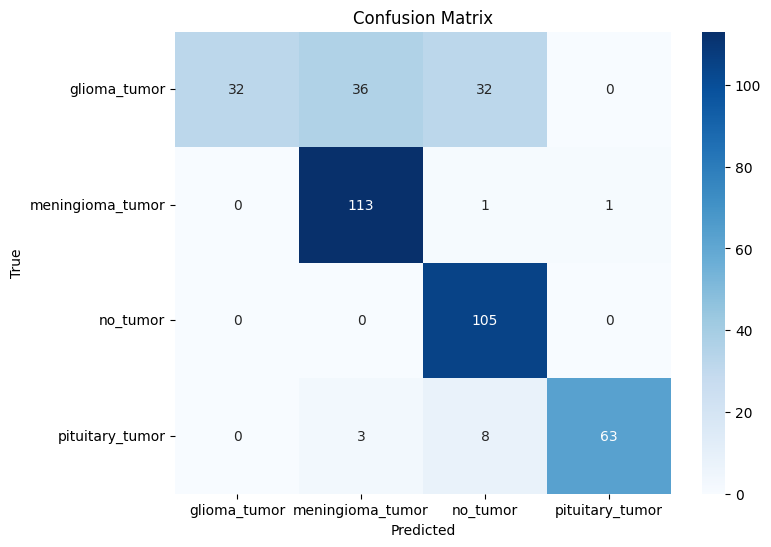

In [4]:
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import cv2
from timm.models.swin_transformer import SwinTransformer
from torchvision.utils import make_grid

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[INFO] Using device: {device}")

# --- Load the best saved model ---
model = timm.create_model('swin_tiny_patch4_window7_224', pretrained=False, num_classes=4)
model.load_state_dict(torch.load('best_swin_transformer.pth', map_location=device))
model.to(device)
model.eval()

# --- Evaluate on validation set ---
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# --- Classification Report ---
print("\n[INFO] Classification Report:")
print(classification_report(all_labels, all_preds, target_names=val_dataset.dataset.classes))

# --- Confusion Matrix ---
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=val_dataset.dataset.classes, yticklabels=val_dataset.dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()



C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


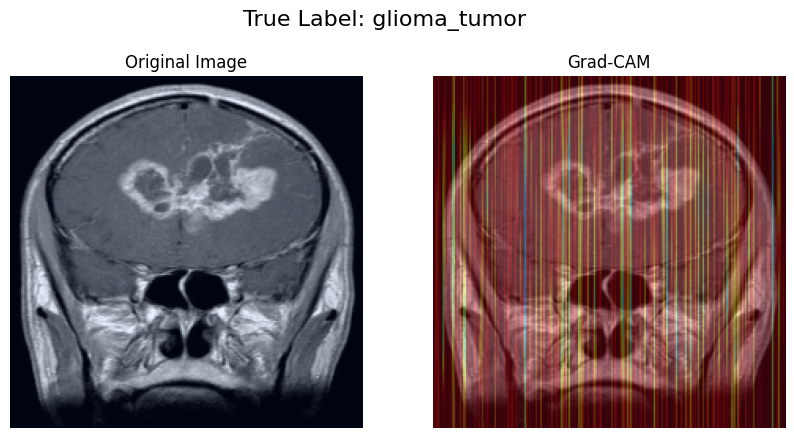

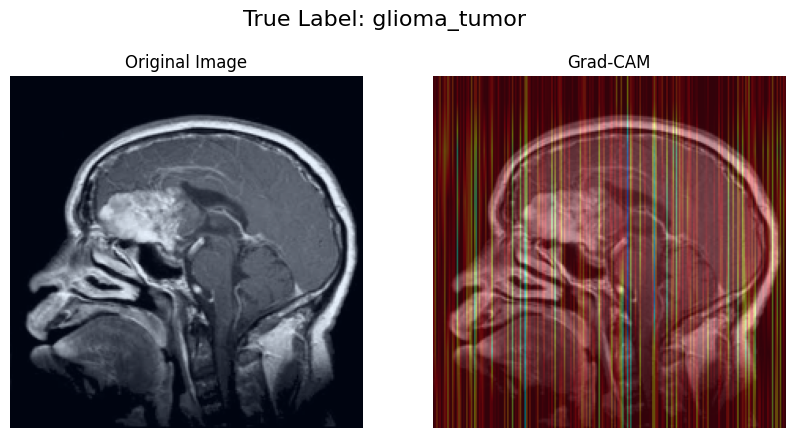

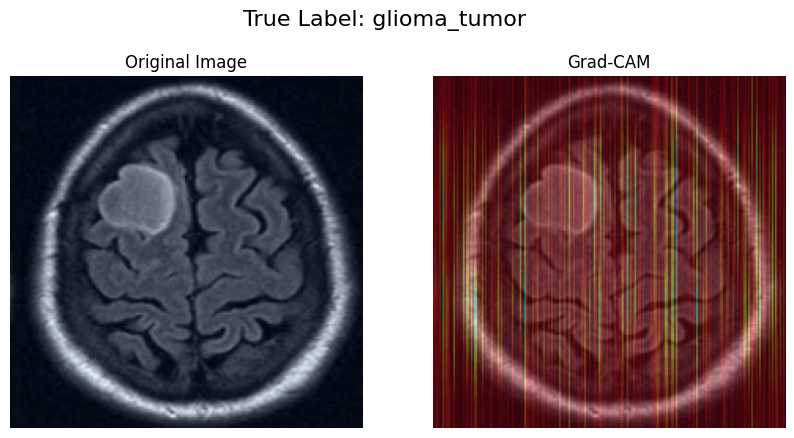

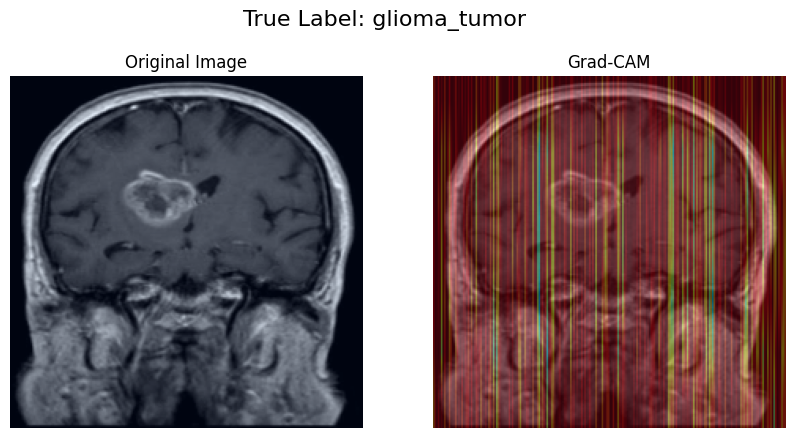

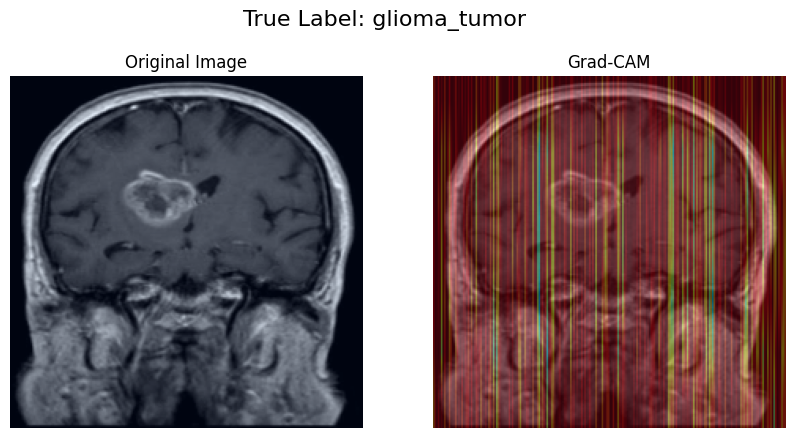

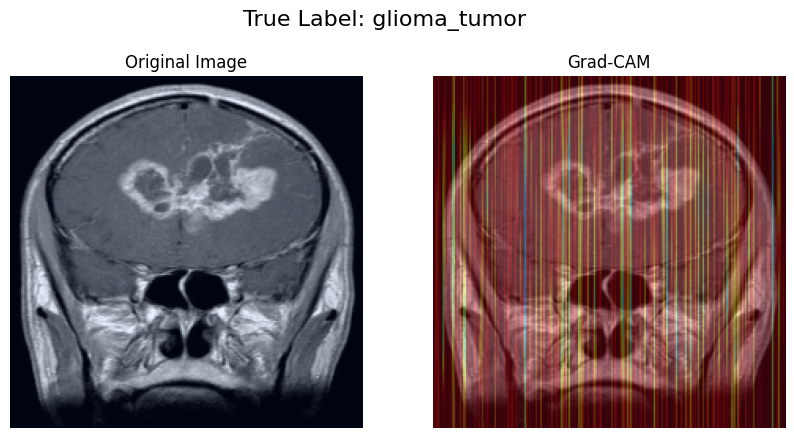

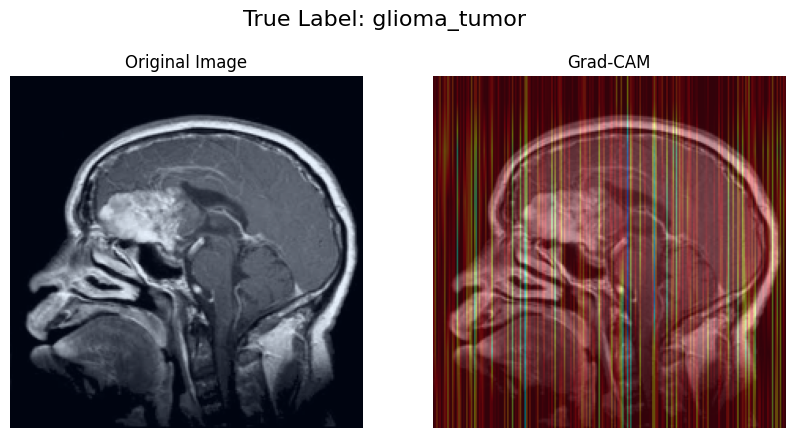

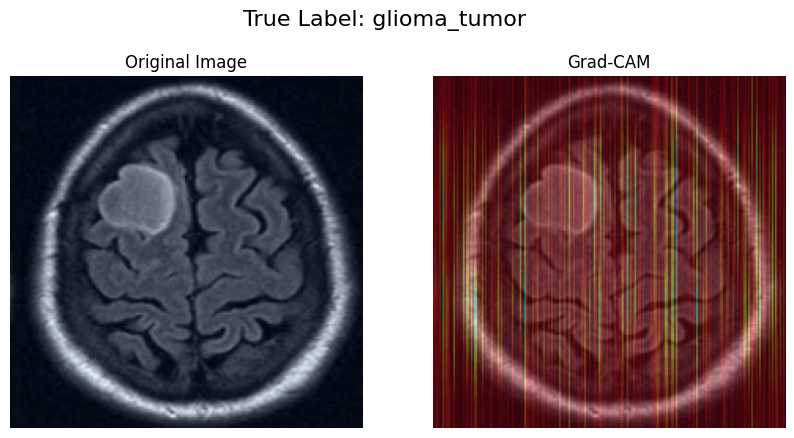

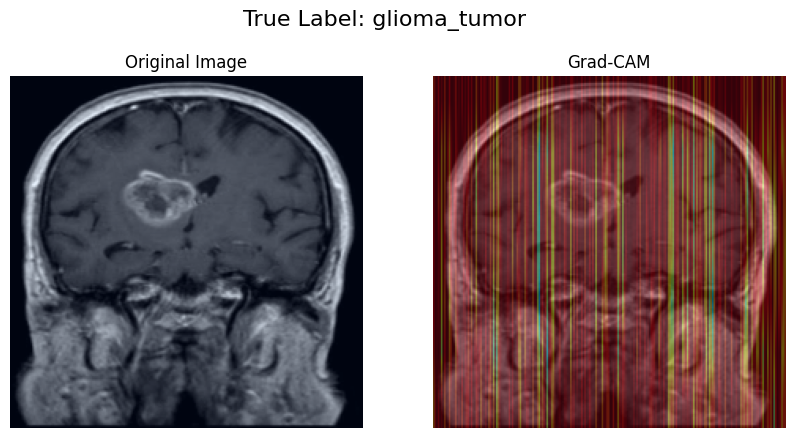

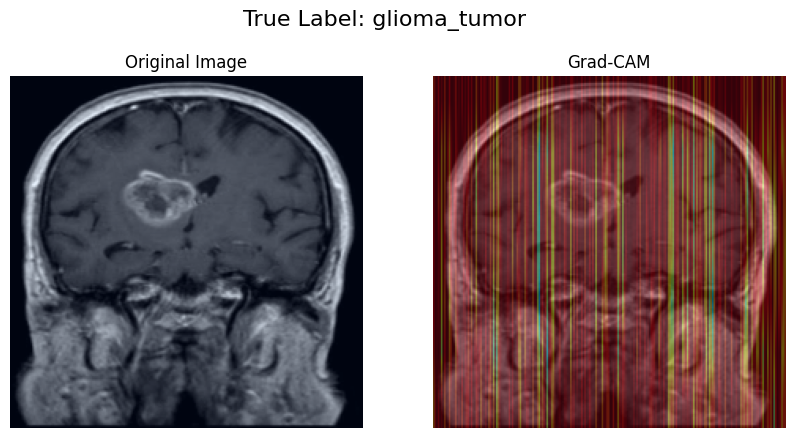

In [5]:
# --- Grad-CAM Implementation ---
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_layers()

    def hook_layers(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate_cam(self, input_tensor, class_idx=None):
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = torch.argmax(output, dim=1)

        loss = output[:, class_idx]
        self.model.zero_grad()
        loss.backward(retain_graph=True)

        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations[0]

        for i in range(activations.shape[0]):
            activations[i, :, :] *= pooled_gradients[i]

        heatmap = activations.mean(dim=0).cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap /= np.max(heatmap) if np.max(heatmap) != 0 else 1

        return heatmap

def visualize_gradcam(model, dataloader, target_layer, num_images=5):
    grad_cam = GradCAM(model, target_layer)

    images_shown = 0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        for i in range(images.size(0)):
            input_tensor = images[i].unsqueeze(0)
            heatmap = grad_cam.generate_cam(input_tensor)

            img = input_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()
            img = (img - img.min()) / (img.max() - img.min())
            img = np.uint8(255 * img)

            heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
            heatmap = np.uint8(255 * heatmap)
            heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

            superimposed_img = cv2.addWeighted(img, 0.6, heatmap, 0.4, 0)

            plt.figure(figsize=(10, 5))
            plt.suptitle(f"True Label: {val_dataset.dataset.classes[labels[i]]}", fontsize=16)
            plt.subplot(1, 2, 1)
            plt.imshow(img)
            plt.title('Original Image')
            plt.axis('off')

            plt.subplot(1, 2, 2)
            plt.imshow(superimposed_img)
            plt.title('Grad-CAM')
            plt.axis('off')

            plt.show()

            images_shown += 1
            if images_shown >= num_images:
                return

# --- Visualize Grad-CAM for Validation Set ---
target_layer = model.norm  # For Swin Transformer, "norm" is the final layer
visualize_gradcam(model, val_loader, target_layer, num_images=5)
# --- Grad-CAM Implementation ---
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_layers()

    def hook_layers(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate_cam(self, input_tensor, class_idx=None):
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = torch.argmax(output, dim=1)

        loss = output[:, class_idx]
        self.model.zero_grad()
        loss.backward(retain_graph=True)

        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations[0]

        for i in range(activations.shape[0]):
            activations[i, :, :] *= pooled_gradients[i]

        heatmap = activations.mean(dim=0).cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap /= np.max(heatmap) if np.max(heatmap) != 0 else 1

        return heatmap

def visualize_gradcam(model, dataloader, target_layer, num_images=5):
    grad_cam = GradCAM(model, target_layer)

    images_shown = 0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        for i in range(images.size(0)):
            input_tensor = images[i].unsqueeze(0)
            heatmap = grad_cam.generate_cam(input_tensor)

            img = input_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()
            img = (img - img.min()) / (img.max() - img.min())
            img = np.uint8(255 * img)

            heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
            heatmap = np.uint8(255 * heatmap)
            heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

            superimposed_img = cv2.addWeighted(img, 0.6, heatmap, 0.4, 0)

            plt.figure(figsize=(10, 5))
            plt.suptitle(f"True Label: {val_dataset.dataset.classes[labels[i]]}", fontsize=16)
            plt.subplot(1, 2, 1)
            plt.imshow(img)
            plt.title('Original Image')
            plt.axis('off')

            plt.subplot(1, 2, 2)
            plt.imshow(superimposed_img)
            plt.title('Grad-CAM')
            plt.axis('off')

            plt.show()

            images_shown += 1
            if images_shown >= num_images:
                return

# --- Visualize Grad-CAM for Validation Set ---
target_layer = model.norm  # For Swin Transformer, "norm" is the final layer
visualize_gradcam(model, val_loader, target_layer, num_images=5)


In [8]:
import torch
import timm  # timm contient swin transformer déjà prêt
import torchvision.transforms as transforms
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[INFO] Using device: {device}")

# --- Load your Swin Transformer ---
model = timm.create_model('swin_tiny_patch4_window7_224', pretrained=False, num_classes=4)  
model.load_state_dict(torch.load('best_swin_transformer.pth', map_location=device))
model = model.to(device)
model.eval()


[INFO] Using device: cuda


C:\Users\bough\AppData\Local\Temp\ipykernel_15484\3160119976.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_swin_transformer.pth

SwinTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  )
  (layers): Sequential(
    (0): SwinTransformerStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): SwinTransformerBlock(
          (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
          (attn): WindowAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=96, out_features=96, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
            (softmax): Softmax(dim=-1)
          )
          (drop_path1): Identity()
          (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU(approximate='none')
            (drop1): 

***Efficientnet_b3a***

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import models
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import copy
import os
import time
import timm
import cv2
from tqdm import tqdm
import seaborn as sns

# Set Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
train_dir = 'Brain-Tumor-Classification-DataSet-master/Training'
val_dir = 'Brain-Tumor-Classification-DataSet-master/Testing'
test_dir = 'Brain-Tumor-Classification-DataSet-master/Testing'

# Transformations
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Datasets
train_dataset = torchvision.datasets.ImageFolder(train_dir, transform=train_transforms)
val_dataset = torchvision.datasets.ImageFolder(val_dir, transform=val_transforms)
test_dataset = torchvision.datasets.ImageFolder(test_dir, transform=val_transforms)

# Dataloaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

class_names = train_dataset.classes
print(f"Classes: {class_names}")


Using device: cuda
Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


In [5]:

# ResNet101
resnet101 = models.resnet101(pretrained=True)
num_features = resnet101.fc.in_features
resnet101.fc = nn.Linear(num_features, 4) 
resnet101 = resnet101.to(device)

# EfficientNet
efficientnet = timm.create_model('efficientnet_b3a', pretrained=True, num_classes=4)
efficientnet = efficientnet.to(device)

# Optimizers
optimizer_resnet = optim.Adam(resnet101.parameters(), lr=1e-4)
optimizer_effnet = optim.Adam(efficientnet.parameters(), lr=1e-4)

# Loss with Label Smoothing
class LabelSmoothingCrossEntropy(nn.Module):
    def __init__(self, smoothing=0.1):
        super(LabelSmoothingCrossEntropy, self).__init__()
        self.smoothing = smoothing

    def forward(self, pred, target):
        log_probs = torch.nn.functional.log_softmax(pred, dim=-1)
        targets = torch.zeros_like(log_probs).scatter_(1, target.unsqueeze(1), 1)
        targets = (1 - self.smoothing) * targets + self.smoothing / pred.size(1)
        loss = (-targets * log_probs).sum(dim=1).mean()
        return loss

criterion = LabelSmoothingCrossEntropy()

# Schedulers
scheduler_resnet = CosineAnnealingLR(optimizer_resnet, T_max=10)
scheduler_effnet = CosineAnnealingLR(optimizer_effnet, T_max=10)


C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\timm\models\_factory.py:126: UserWarning: Mapping deprecated model name efficientnet_b3a to current efficientnet_b3.
  model = create_fn(


In [6]:
import os
import copy
import time
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix

# Device

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on {device}...")

# Hyperparameters

num_epochs = 30
patience = 5  
best_val_acc = 0
learning_rate = 1e-4

# Loss Function and Optimizer
# Fusion de ResNet101 et EfficientNet (version plus légère)
class FusionModel(nn.Module):
    def __init__(self, num_classes=4):
        super(FusionModel, self).__init__()
        self.resnet101 = models.resnet101(pretrained=True)
        self.efficientnet = timm.create_model('efficientnet_b0', pretrained=True)  # Version plus légère

        # Modifier les têtes pour qu'elles donnent un output de taille 512
        self.resnet101.fc = nn.Linear(self.resnet101.fc.in_features, 512)
        self.efficientnet.classifier = nn.Linear(self.efficientnet.classifier.in_features, 512)

        # Fusion + dernière couche de classification
        self.classifier = nn.Sequential(
            nn.Linear(512*2, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        out1 = self.resnet101(x)
        out2 = self.efficientnet(x)
        out = torch.cat((out1, out2), dim=1)
        out = self.classifier(out)
        return out

# Instantiate model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = FusionModel(num_classes=4).to(device)


criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Early Stopping Class

class EarlyStopping:
    def __init__(self, patience=7, verbose=False):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss, model):
        if self.best_loss is None or val_loss < self.best_loss:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

# Initialize early stopping

early_stopping = EarlyStopping(patience=patience, verbose=True)

# Training and Validation Loop

train_losses = []
val_losses = []

best_model_wts = copy.deepcopy(model.state_dict())

for epoch in range(num_epochs):
    print(f'Epoch {epoch+1}/{num_epochs}')
    print('-' * 30)

    # Train
    model.train()
    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in tqdm(train_loader):
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = running_corrects.double() / len(train_dataset)

    train_losses.append(epoch_loss)

    # Validation
    model.eval()
    val_running_loss = 0.0
    val_running_corrects = 0

    with torch.no_grad():
        for inputs, labels in tqdm(val_loader):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * inputs.size(0)
            val_running_corrects += torch.sum(preds == labels.data)

    val_loss = val_running_loss / len(val_dataset)
    val_acc = val_running_corrects.double() / len(val_dataset)

    val_losses.append(val_loss)

    print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
    print(f'Val   Loss: {val_loss:.4f} Acc: {val_acc:.4f}')

    # Save Best Model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), 'best_brain_tumor_model.pth')
        print("Best model saved!")

    # Check early stopping
    early_stopping(val_loss, model)

    if early_stopping.early_stop:
        print("Early stopping triggered")
        break

# Load best model weights
model.load_state_dict(best_model_wts)

Training on cuda...
Epoch 1/30
------------------------------


100%|██████████████████████████████████████████████████████████████████████████████████| 13/13 [00:18<00:00,  1.45s/it]


Train Loss: 0.4736 Acc: 0.8240
Val   Loss: 1.1509 Acc: 0.6421
Best model saved!
Epoch 2/30
------------------------------


100%|██████████████████████████████████████████████████████████████████████████████████| 13/13 [00:15<00:00,  1.22s/it]


Train Loss: 0.1704 Acc: 0.9415
Val   Loss: 1.3375 Acc: 0.6827
Best model saved!
Epoch 3/30
------------------------------


...

100%|██████████████████████████████████████████████████████████████████████████████████| 13/13 [00:19<00:00,  1.53s/it]


Train Loss: 0.0544 Acc: 0.9833
Val   Loss: 1.4020 Acc: 0.7462
Best model saved!
Epoch 6/30
------------------------------


100%|██████████████████████████████████████████████████████████████████████████████████| 13/13 [00:21<00:00,  1.64s/it]


Train Loss: 0.0390 Acc: 0.9868
Val   Loss: 1.3616 Acc: 0.7792
Best model saved!
Early stopping triggered


<All keys matched successfully>

In [7]:
# Evaluation

def evaluate_model(model, dataloader, class_names):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in tqdm(dataloader):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    print(classification_report(y_true, y_pred, target_names=class_names))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

In [8]:
# Inference Function

def inference(image_path, model, transform, class_names):
    from PIL import Image
    model.eval()
    image = Image.open(image_path).convert('RGB')
    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image)
        prob = torch.nn.functional.softmax(output, dim=1)
        confidence, pred = torch.max(prob, 1)

    print(f"Predicted Class: {class_names[pred.item()]} with confidence {confidence.item()*100:.2f}%")

    return pred.item(), confidence.item()

In [9]:
# Grad-CAM Visualization

def generate_gradcam(model, img_path, transform, target_layer, class_idx=None):
    from torchvision import transforms
    import matplotlib.pyplot as plt
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image

    img = Image.open(img_path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    cam = GradCAM(model=model, target_layers=[target_layer], use_cuda=torch.cuda.is_available())

    targets = None
    if class_idx is not None:
        from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
        targets = [ClassifierOutputTarget(class_idx)]

    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)

    grayscale_cam = grayscale_cam[0, :]
    img = np.array(img) / 255.0
    visualization = show_cam_on_image(img, grayscale_cam, use_rgb=True)

    plt.figure(figsize=(8,8))
    plt.imshow(visualization)
    plt.axis('off')
    plt.show()

    return visualization


***ResNet101 + EfficientNetB0***

In [10]:
import torch
import torch.nn as nn
import torchvision.models as models
import timm

# Fusion de ResNet101 + EfficientNetB0
class FusionModel(nn.Module):
    def __init__(self, num_classes=4):
        super(FusionModel, self).__init__()
        self.resnet101 = models.resnet101(weights=models.ResNet101_Weights.DEFAULT)
        self.efficientnet = timm.create_model('efficientnet_b0', pretrained=True)

        self.resnet101.fc = nn.Linear(self.resnet101.fc.in_features, 512)
        self.efficientnet.classifier = nn.Linear(self.efficientnet.classifier.in_features, 512)

        self.classifier = nn.Sequential(
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        out1 = self.resnet101(x)
        out2 = self.efficientnet(x)
        out = torch.cat((out1, out2), dim=1)
        out = self.classifier(out)
        return out


In [19]:
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

# Directories
train_dir = 'Brain-Tumor-Classification-DataSet-master/Training'
val_dir = 'Brain-Tumor-Classification-DataSet-master/Testing'

# Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# Datasets and Loaders
train_dataset = ImageFolder(root=train_dir, transform=transform)
val_dataset = ImageFolder(root=val_dir, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Model, Optimizer, Loss
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = FusionModel(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


In [11]:
class EarlyStopping:
    def __init__(self, patience=7, verbose=False):
        self.patience = patience
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.verbose = verbose

    def __call__(self, val_loss, model, path):
        if self.best_loss is None or val_loss < self.best_loss:
            self.best_loss = val_loss
            self.save_checkpoint(model, path)
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def save_checkpoint(self, model, path):
        torch.save(model.state_dict(), path)


In [12]:
import time
from torch.cuda.amp import GradScaler, autocast

num_epochs = 50
early_stopping = EarlyStopping(patience=5, verbose=True)
scaler = GradScaler()

best_model_path = 'best_modelFus.pth'

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        with autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss /= len(val_loader)
    val_acc = 100. * val_correct / val_total

    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

    early_stopping(val_loss, model, best_model_path)

    if early_stopping.early_stop:
        print("Early stopping triggered!")
        break


C:\Users\bough\AppData\Local\Temp\ipykernel_23328\2017477196.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
C:\Users\bough\AppData\Local\Temp\ipykernel_23328\2017477196.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch [1/50], Train Loss: 0.0649, Train Acc: 97.84%, Val Loss: 1.2885, Val Acc: 78.43%
Epoch [2/50], Train Loss: 0.0409, Train Acc: 98.89%, Val Loss: 1.0464, Val Acc: 78.93%
Epoch [3/50], Train Loss: 0.0537, Train Acc: 98.50%, Val Loss: 1.3227, Val Acc: 78.68%
Epoch [4/50], Train Loss: 0.0271, Train Acc: 99.41%, Val Loss: 1.1374, Val Acc: 80.46%
Epoch [5/50], Train Loss: 0.0360, Train Acc: 98.89%, Val Loss: 1.5011, Val Acc: 78.43%
Epoch [6/50], Train Loss: 0.0167, Train Acc: 99.44%, Val Loss: 1.4819, Val Acc: 79.70%
Epoch [7/50], Train Loss: 0.0146, Train Acc: 99.58%, Val Loss: 1.7128, Val Acc: 78.43%
Early stopping triggered!


In [26]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

def visualize_gradcam(model, img_path, class_idx=None):
    model.eval()

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_tensor = transform(Image.fromarray(img)).unsqueeze(0).to(device)

    # Forward
    output = model(img_tensor)
    pred_class = output.argmax(dim=1).item() if class_idx is None else class_idx

    # Backward
    one_hot = torch.zeros((1, output.size()[-1]), device=device)
    one_hot[0][pred_class] = 1
    output.backward(gradient=one_hot)

    # Gradients
    gradients = model.resnet101.layer4[2].conv3.weight.grad
    pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])

    activations = model.resnet101.layer4[2].conv3(img_tensor).detach()
    for i in range(activations.shape[1]):
        activations[:, i, :, :] *= pooled_gradients[i]

    heatmap = torch.mean(activations, dim=1).squeeze()
    heatmap = np.maximum(heatmap.cpu(), 0)
    heatmap /= torch.max(heatmap)

    heatmap = heatmap.numpy()
    plt.matshow(heatmap)
    plt.show()

    # Superimpose
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    superimposed_img = heatmap * 0.4 + img

    plt.figure(figsize=(8, 8))
    plt.imshow(superimposed_img.astype('uint8'))
    plt.axis('off')
    plt.show()


In [21]:
from PIL import Image

def predict_image(model, img_path, classes):
    model.eval()
    img = Image.open(img_path)
    img_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(img_tensor)
        _, preds = torch.max(outputs, 1)
        confidence = torch.nn.functional.softmax(outputs, dim=1)[0][preds].item()

    print(f"Prediction: {classes[preds.item()]} with confidence {confidence*100:.2f}%")
    visualize_gradcam(model, img_path)


In [28]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image

# Define your transform if not done
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# Grad-CAM function
def visualize_gradcam(model, img_path, target_layer='layer4'):
    model.eval()
    img = Image.open(img_path).convert('RGB')
    img_tensor = transform(img).unsqueeze(0).to(device)

    # Hook the activations and gradients
    activations = {}
    gradients = {}

    def forward_hook(module, input, output):
        activations['value'] = output

    def backward_hook(module, grad_in, grad_out):
        gradients['value'] = grad_out[0]

    # Register hooks on the target layer
    target_module = dict([*model.resnet101.named_modules()])[target_layer]
    forward_handle = target_module.register_forward_hook(forward_hook)
    backward_handle = target_module.register_backward_hook(backward_hook)

    # Forward pass
    output = model(img_tensor)
    pred_class = output.argmax().item()

    # Backward pass
    model.zero_grad()
    class_loss = output[0, pred_class]
    class_loss.backward()

    # Remove hooks
    forward_handle.remove()
    backward_handle.remove()

    # Get activation and gradient
    act = activations['value'].squeeze(0).detach().cpu()
    grad = gradients['value'].squeeze(0).detach().cpu()

    weights = grad.mean(dim=(1, 2))
    cam = torch.zeros(act.shape[1:], dtype=torch.float32)

    for i, w in enumerate(weights):
        cam += w * act[i]

    cam = np.maximum(cam.numpy(), 0)
    cam = cv2.resize(cam, (224, 224))
    cam -= cam.min()
    cam /= cam.max()

    # Overlay
    img_np = np.array(img.resize((224, 224)))
    heatmap = (cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET) * 0.4).astype(np.uint8)
    superimposed_img = cv2.addWeighted(img_np, 0.6, heatmap, 0.4, 0)

    plt.imshow(superimposed_img)
    plt.axis('off')
    plt.title(f'Grad-CAM for class: {classes[pred_class]}')
    plt.show()


C:\Users\bough\AppData\Local\Temp\ipykernel_23328\776344268.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Prediction: glioma_tumor with confidence 54.98%


C:\Users\bough\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


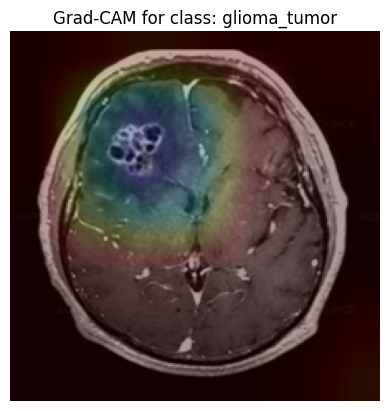

In [29]:
# Load the best model
model.load_state_dict(torch.load(best_model_path))
model.eval()

# Classes
classes = train_dataset.classes

# Example
predict_image(model, 'Brain-Tumor-Classification-DataSet-master/Testing/glioma_tumor/image(95).jpg', classes)


Prediction: meningioma_tumor with confidence 99.95%


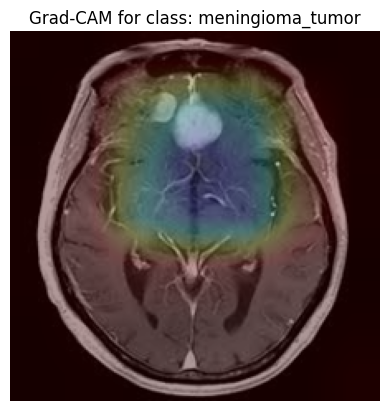

In [30]:
predict_image(model, 'Brain-Tumor-Classification-DataSet-master/Testing/meningioma_tumor/image(94).jpg', classes)


Prediction: meningioma_tumor with confidence 99.96%


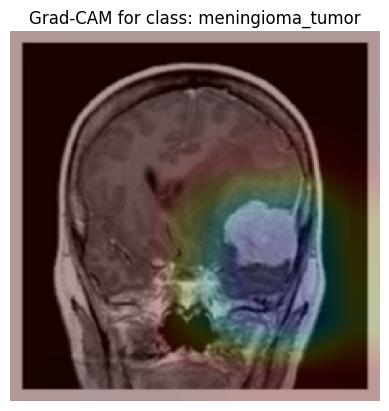

In [31]:
predict_image(model, 'Brain-Tumor-Classification-DataSet-master/Testing/meningioma_tumor/image(123).jpg', classes)


Prediction: no_tumor with confidence 99.95%


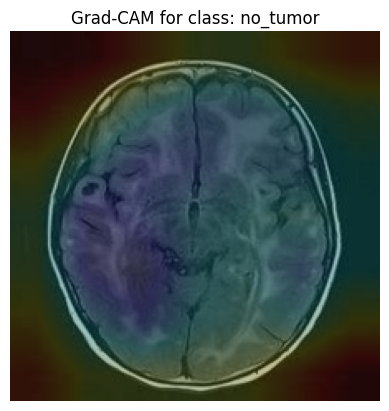

In [32]:
predict_image(model, 'Brain-Tumor-Classification-DataSet-master/Testing/no_tumor/image(71).jpg', classes)


Prediction: pituitary_tumor with confidence 99.93%


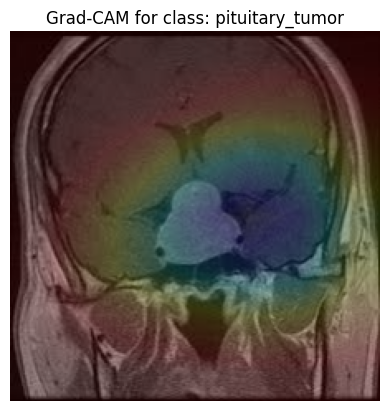

In [33]:
predict_image(model, 'Brain-Tumor-Classification-DataSet-master/Testing/pituitary_tumor/image(57).jpg', classes)


Prediction: no_tumor with confidence 99.52%


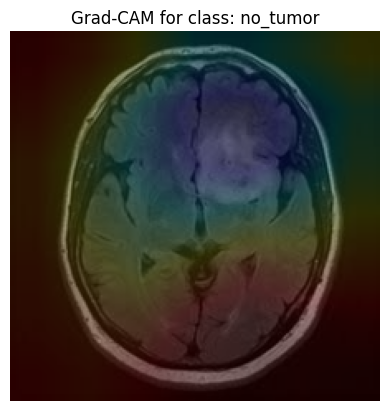

In [34]:
predict_image(model, 'Brain-Tumor-Classification-DataSet-master/Testing/glioma_tumor/image(3).jpg', classes)


In [3]:
!pip install efficientnet_pytorch

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for efficientnet_pytorch: filename=efficientnet_pytorch-0.7.1-py3-none-any.whl size=16521 sha256=e700a67593af7866a4815fb1f0ed39aaa9188e007844de6dde7fc4a43bc23a08
  Stored in directory: c:\users\bough\appdata\local\pip\cache\wheels\03\3f\e9\911b1bc46869644912bda90a56bcf7b960f20b5187feea3baf
Successfully built efficientnet_pytorch



[notice] A new release of pip is available: 25.0.1 -> 25.1
[notice] To update, run: python.exe -m pip install --upgrade pip


***La Segmentation***

In [15]:
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset
from PIL import Image
import os
import torch

class BrainTumorMultiTaskDataset(Dataset):
    def __init__(self, root_dir, transform=None, fake_segmentation=True):
        self.class_dataset = ImageFolder(root=root_dir, transform=transform)
        self.fake_segmentation = fake_segmentation

    def __len__(self):
        return len(self.class_dataset)

    def __getitem__(self, idx):
        image, label = self.class_dataset[idx]

        # Simulated segmentation mask (dummy tensor with same spatial size)
        if self.fake_segmentation:
            # Simulate a fake mask: for real use, load an actual mask image
            seg_mask = torch.zeros((image.size(1), image.size(2)))  # H x W
        else:
            # Load actual mask here (if you have them)
            pass

        return image, (label, seg_mask)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])
from torch.utils.data import DataLoader

train_dataset = BrainTumorMultiTaskDataset('Brain-Tumor-Classification-DataSet-master/Training', transform=transform)
val_dataset = BrainTumorMultiTaskDataset('Brain-Tumor-Classification-DataSet-master/Testing', transform=transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)


In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
import os

def train_model(model, dataloader, val_loader, num_classes, num_epochs, device, checkpoint_path):
    model.to(device)

    # Define losses
    classification_criterion = nn.CrossEntropyLoss()
    segmentation_criterion = nn.BCELoss()

    # Optimizer
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    # Best validation loss
    best_val_loss = float('inf')

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for inputs, (labels, masks) in tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            inputs = inputs.to(device)
            labels = labels.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()

            class_outputs, seg_outputs = model(inputs)

            loss_cls = classification_criterion(class_outputs, labels)
            loss_seg = segmentation_criterion(seg_outputs.squeeze(1), masks.float())

            loss = loss_cls + loss_seg
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_train_loss = running_loss / len(dataloader)

        # Validation
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for inputs, (labels, masks) in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                masks = masks.to(device)

                class_outputs, seg_outputs = model(inputs)

                loss_cls = classification_criterion(class_outputs, labels)
                loss_seg = segmentation_criterion(seg_outputs.squeeze(1), masks.float())

                loss = loss_cls + loss_seg
                val_loss += loss.item()

                # Accuracy
                _, predicted = torch.max(class_outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        avg_val_loss = val_loss / len(val_loader)
        val_acc = correct / total

        print(f"Epoch {epoch+1} - Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

        # Save best model
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), os.path.join(checkpoint_path, "best_best_model.pth"))
            print(" Best model saved.")

    print("Training finished.")


In [17]:
import torch
import torch.nn as nn
from efficientnet_pytorch import EfficientNet
import torch.nn.functional as F

class MultiTaskModel(nn.Module):
    def __init__(self, num_classes):
        super(MultiTaskModel, self).__init__()
        
        # Load EfficientNet backbone
        self.backbone = EfficientNet.from_pretrained('efficientnet-b0')
        self.encoder_channels = 1280  # Output channels from EfficientNet-B0
        
        # Classification head
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(self.encoder_channels, num_classes)
        )

        # Segmentation decoder (U-Net style)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(self.encoder_channels, 256, kernel_size=2, stride=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 1, kernel_size=1),
            nn.Sigmoid()  # Binary segmentation
        )

    def forward(self, x):
        # Backbone feature extractor
        features = self.backbone.extract_features(x)  # Shape: [B, 1280, H, W], typically [B, 1280, 7, 7]
        
        # Classification branch
        cls_out = self.classifier(features)  # Shape: [B, num_classes]
        
        # Segmentation branch
        seg_out = self.decoder(features)  # Shape: [B, 1, H', W'], e.g., [B, 1, 28, 28]
        seg_out = F.interpolate(seg_out, size=x.shape[2:], mode='bilinear', align_corners=False)  # Resize to input size
        
        return cls_out, seg_out


In [18]:
print("Class indices:", train_dataset.class_dataset.class_to_idx)


Class indices: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}


In [19]:
import glob

classification_root = 'Brain-Tumor-Classification-DataSet-master/Training'
class_map = {'glioma': 0, 'meningioma': 1, 'pituitary': 2, 'no_tumor': 3}

cls_image_paths = []
cls_labels = []

for class_name, class_idx in class_map.items():
    img_paths = glob.glob(os.path.join(classification_root, class_name, '*.jpg'))
    cls_image_paths.extend(img_paths)
    cls_labels.extend([class_idx] * len(img_paths))


In [20]:
seg_image_paths = sorted(glob.glob('archive/images/*.jpg'))
seg_mask_paths = sorted(glob.glob('archive/masks/*.jpg'))


In [21]:
# Créer un dictionnaire de noms de fichiers sans chemins
imgname_to_label = {os.path.basename(p): l for p, l in zip(cls_image_paths, cls_labels)}

seg_labels = []
final_seg_images = []
final_seg_masks = []

for img_path, mask_path in zip(seg_image_paths, seg_mask_paths):
    fname = os.path.basename(img_path)
    if fname in imgname_to_label:
        final_seg_images.append(img_path)
        final_seg_masks.append(mask_path)
        seg_labels.append(imgname_to_label[fname])


In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

# ----------- Dataset pour la segmentation -----------
class SegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.image_names = sorted([f for f in os.listdir(image_dir) if f.endswith((".jpg", ".png"))])

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        img_name = self.image_names[idx]
        img_path = os.path.join(self.image_dir, img_name)
        mask_path = os.path.join(self.mask_dir, img_name.replace(".jpg", ".png"))

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)

        return image, mask

# ----------- Modèle de segmentation avec EfficientNet -----------

class SegmentationModel(nn.Module):
    def __init__(self):
        super(SegmentationModel, self).__init__()
        backbone = models.efficientnet_b0(pretrained=True)
        self.encoder = backbone.features  # donne [batch, 1280, 7, 7]

        # Décodeur simple pour upsampler jusqu'à taille originale (par ex: 224x224)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(1280, 512, kernel_size=2, stride=2),  # 7x7 → 14x14
            nn.ReLU(),
            nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2),   # 14x14 → 28x28
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2),   # 28x28 → 56x56
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),    # 56x56 → 112x112
            nn.ReLU(),
            nn.ConvTranspose2d(64, 1, kernel_size=2, stride=2),      # 112x112 → 224x224
            nn.Sigmoid()  # pour sortie binaire (0-1)
        )

    def forward(self, x):
        features = self.encoder(x)  # [B, 1280, 7, 7]
        seg_out = self.decoder(features)  # [B, 1, 224, 224]
        return seg_out

# ----------- Fonction d'entraînement -----------
def train_segmentation_model():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
    ])

    dataset = SegmentationDataset(image_dir="archive/images", mask_dir="archive/masks", transform=transform)
    loader = DataLoader(dataset, batch_size=8, shuffle=True)

    model = SegmentationModel().to(device)
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    for epoch in range(5):
        total_loss = 0
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)

            outputs = model(imgs)
            loss = criterion(outputs, masks)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}, Loss: {total_loss / len(loader):.4f}")

    torch.save(model.state_dict(), "segmentation_model.pth")
    print("Model saved.")

if __name__ == "__main__":
    train_segmentation_model()


Using device: cuda
Epoch 1, Loss: 0.0934
Epoch 2, Loss: 0.0360
Epoch 3, Loss: 0.0308
Epoch 4, Loss: 0.0246
Epoch 5, Loss: 0.0199
Model saved.


Using device: cuda


C:\Users\bough\AppData\Local\Temp\ipykernel_16588\203399766.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path))


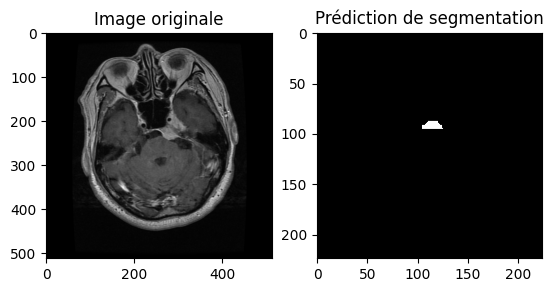

Using device: cuda


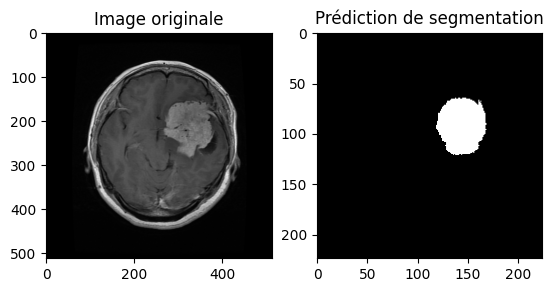

Using device: cuda


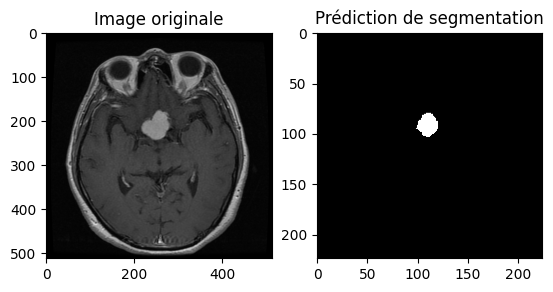

Using device: cuda


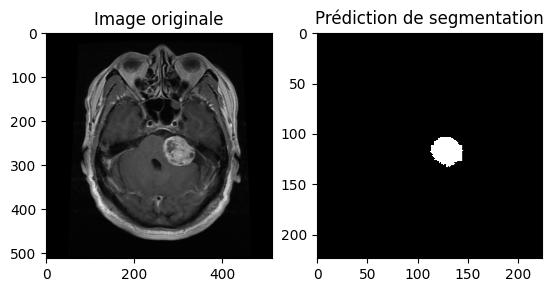

Using device: cuda


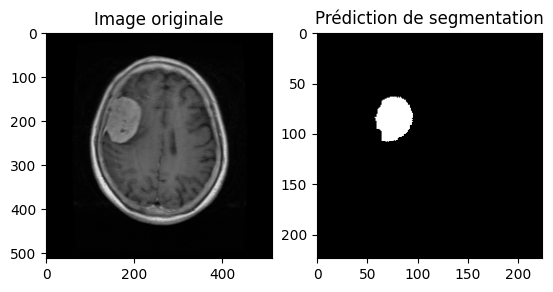

In [29]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import models

# ----------- Fonction de test -----------
def test_segmentation_model(model_path, image_path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # Charger le modèle
    model = SegmentationModel().to(device)
    model.load_state_dict(torch.load(model_path))
    model.eval()  # Mettre le modèle en mode évaluation

    # Définir les transformations pour l'image
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
    ])

    # Charger l'image et appliquer les transformations
    image = Image.open(image_path).convert("RGB")
    input_image = transform(image).unsqueeze(0).to(device)  # Ajouter la dimension batch

    # Passer l'image à travers le modèle
    with torch.no_grad():
        output = model(input_image)

    # Convertir le résultat en numpy et appliquer un seuil
    output = output.squeeze().cpu().numpy()  # Retirer la dimension du batch et transformer en numpy
    output = (output > 0.5).astype(int)  # Appliquer un seuil pour obtenir un masque binaire

    # Afficher l'image originale et la prédiction
    plt.subplot(1, 2, 1)
    plt.title("Image originale")
    plt.imshow(image)

    plt.subplot(1, 2, 2)
    plt.title("Prédiction de segmentation")
    plt.imshow(output, cmap='gray')  # Afficher le masque avec une échelle de gris

    plt.show()

# Utilisation de la fonction de test
test_segmentation_model("segmentation_model.pth", r"archive/images/6.png")
test_segmentation_model("segmentation_model.pth", r"archive/images/3.png")
test_segmentation_model("segmentation_model.pth", r"archive/images/40.png")
test_segmentation_model("segmentation_model.pth", r"archive/images/43.png")
test_segmentation_model("segmentation_model.pth", r"archive/images/46.png")


***Multi-Task Learning - Classification + Segmentation (U-Net with EfficientNet backbone)***

=========================================================================================================

In [2]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from efficientnet_pytorch import EfficientNet
from PIL import Image

# --- 1. MultiTask Model Definition ---
class MultiTaskModel(nn.Module):
    def __init__(self, num_classes=4):
        super(MultiTaskModel, self).__init__()
        self.backbone = EfficientNet.from_pretrained('efficientnet-b0')
        self.encoder_channels = 1280

        # Classification Head
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(self.encoder_channels, num_classes)
        )

        # Segmentation Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(self.encoder_channels, 256, kernel_size=2, stride=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 1, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.backbone.extract_features(x)  # (B, 1280, 7, 7)
        cls_out = self.classifier(features)
        seg_out = self.decoder(features)
        seg_out = nn.functional.interpolate(seg_out, size=x.shape[2:], mode='bilinear')
        return cls_out, seg_out

# --- 2. Segmentation Dataset ---
class SegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None, mask_transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_names = sorted(os.listdir(image_dir))
        self.transform = transform
        self.mask_transform = mask_transform

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        image_name = self.image_names[idx]
        img_path = os.path.join(self.image_dir, image_name)
        mask_path = os.path.join(self.mask_dir, image_name)

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        if self.transform:
            image = self.transform(image)
        if self.mask_transform:
            mask = self.mask_transform(mask)

        return image, mask

# --- 3. Classification Dataset ---
from torchvision.datasets import ImageFolder

transform_class = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

transform_mask = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_class_dataset = ImageFolder("Brain-Tumor-Classification-DataSet-master/Training", transform=transform_class)
train_class_loader = DataLoader(train_class_dataset, batch_size=16, shuffle=True)

train_seg_dataset = SegmentationDataset("archive/images", "archive/masks", transform=transform_class, mask_transform=transform_mask)
train_seg_loader = DataLoader(train_seg_dataset, batch_size=16, shuffle=True)

# --- 4. Training ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MultiTaskModel(num_classes=4).to(device)

criterion_class = nn.CrossEntropyLoss()
criterion_seg = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 10
for epoch in range(EPOCHS):
    model.train()
    total_cls_loss = 0
    total_seg_loss = 0

    for images, labels in train_class_loader:
        images, labels = images.to(device), labels.to(device)
        outputs, _ = model(images)
        loss = criterion_class(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_cls_loss += loss.item()

    for images, masks in train_seg_loader:
        images, masks = images.to(device), masks.to(device)
        _, seg_out = model(images)
        loss = criterion_seg(seg_out, masks)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_seg_loss += loss.item()

    print(f"Epoch {epoch+1}/{EPOCHS} | Classification Loss: {total_cls_loss:.4f} | Segmentation Loss: {total_seg_loss:.4f}")

# Save model
torch.save(model.state_dict(), "model_multitask.pth")


Loaded pretrained weights for efficientnet-b0
Epoch 1/10 | Classification Loss: 103.3468 | Segmentation Loss: 26.6039
Epoch 2/10 | Classification Loss: 29.3373 | Segmentation Loss: 8.1419
Epoch 3/10 | Classification Loss: 20.1119 | Segmentation Loss: 6.8789
Epoch 4/10 | Classification Loss: 12.2631 | Segmentation Loss: 6.0927
Epoch 5/10 | Classification Loss: 6.5467 | Segmentation Loss: 5.5704
Epoch 6/10 | Classification Loss: 6.2547 | Segmentation Loss: 5.3492
Epoch 7/10 | Classification Loss: 5.2343 | Segmentation Loss: 5.0079
Epoch 8/10 | Classification Loss: 4.6649 | Segmentation Loss: 4.7547
Epoch 9/10 | Classification Loss: 4.7708 | Segmentation Loss: 4.6651
Epoch 10/10 | Classification Loss: 1.6408 | Segmentation Loss: 4.4697


In [10]:
pip install matplotlib scikit-learn seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 25.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
import numpy as np

def compute_iou(pred_mask, true_mask, threshold=0.5):
    pred_mask = (pred_mask > threshold).float()
    intersection = (pred_mask * true_mask).sum((1,2,3))
    union = ((pred_mask + true_mask) >= 1).float().sum((1,2,3))
    iou = intersection / (union + 1e-6)
    return iou.mean().item()

def evaluate_and_visualize(model, class_loader, seg_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    all_ious = []
    loss_class = nn.CrossEntropyLoss()
    loss_seg = nn.BCELoss()

    total_class_loss = 0
    total_seg_loss = 0

    with torch.no_grad():
        for images, labels in class_loader:
            images, labels = images.to(device), labels.to(device)
            outputs, _ = model(images)
            loss = loss_class(outputs, labels)
            total_class_loss += loss.item()

            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_confidences.extend(probs.max(dim=1).values.cpu().numpy())

        for images, masks in seg_loader:
            images, masks = images.to(device), masks.to(device)
            _, seg_preds = model(images)
            loss = loss_seg(seg_preds, masks)
            total_seg_loss += loss.item()
            iou = compute_iou(seg_preds, masks)
            all_ious.append(iou)

    avg_acc = accuracy_score(all_labels, all_preds)
    avg_conf = np.mean(all_confidences)
    avg_iou = np.mean(all_ious)

    print(" Evaluation Résultats :")
    print(f"Classification Loss: {total_class_loss:.4f}")
    print(f"Segmentation Loss: {total_seg_loss:.4f}")
    print(f"Accuracy: {avg_acc:.4f}")
    print(f"Confidence moyenne: {avg_conf*100:.2f}%")
    print(f"IoU moyen: {avg_iou:.4f}")
    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds))

    # Matrice de confusion
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title("Matrice de confusion")
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.show()

    # Histogramme des confiances
    plt.figure()
    plt.hist(all_confidences, bins=20, color='green', alpha=0.7)
    plt.title("Distribution des confiances")
    plt.xlabel("Confidence")
    plt.ylabel("Nombre")
    plt.show()

    # Échantillons aléatoires de segmentation
    print("\n Affichage d'exemples de segmentation...")
    images, masks = next(iter(seg_loader))
    images, masks = images.to(device), masks.to(device)
    _, seg_preds = model(images)

    for i in range(3):
        plt.figure(figsize=(12,4))
        plt.subplot(1,3,1)
        plt.imshow(images[i].cpu().permute(1,2,0))
        plt.title("Image originale")

        plt.subplot(1,3,2)
        plt.imshow(masks[i][0].cpu(), cmap='gray')
        plt.title("Masque réel")

        plt.subplot(1,3,3)
        plt.imshow(seg_preds[i][0].cpu().detach().numpy() > 0.5, cmap='gray')
        plt.title("Masque prédit")
        plt.show()


 Evaluation Résultats :
Classification Loss: 2.3067
Segmentation Loss: 3.8068
Accuracy: 0.9993
Confidence moyenne: 99.80%
IoU moyen: 0.5467

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       826
           1       1.00      1.00      1.00       822
           2       1.00      1.00      1.00       395
           3       1.00      1.00      1.00       827

    accuracy                           1.00      2870
   macro avg       1.00      1.00      1.00      2870
weighted avg       1.00      1.00      1.00      2870



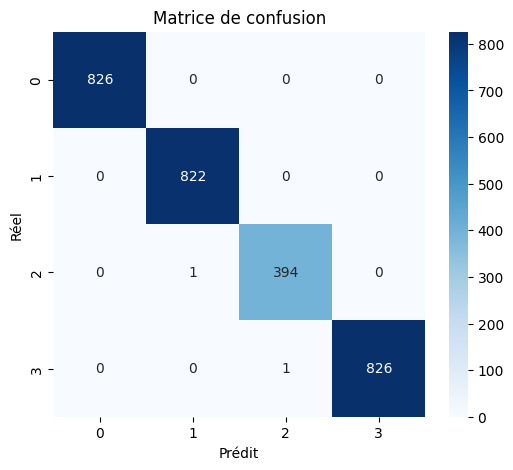

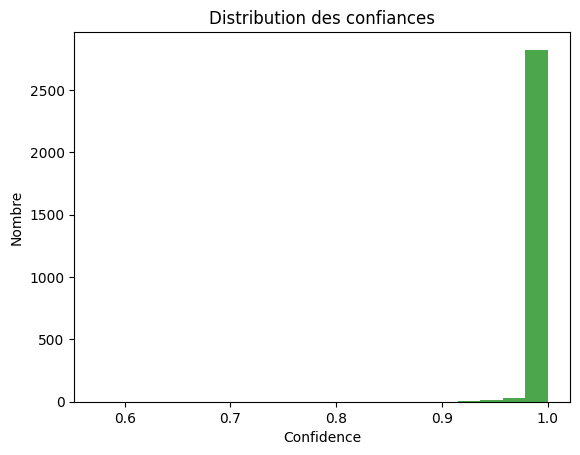


 Affichage d'exemples de segmentation...


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.0996952].


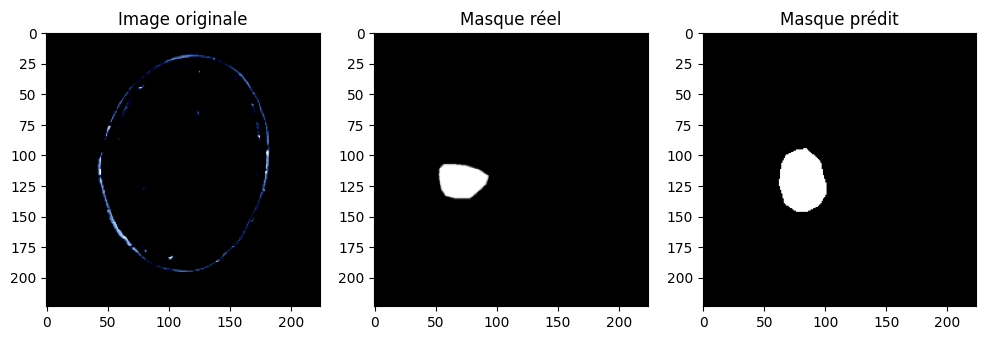

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2914162].


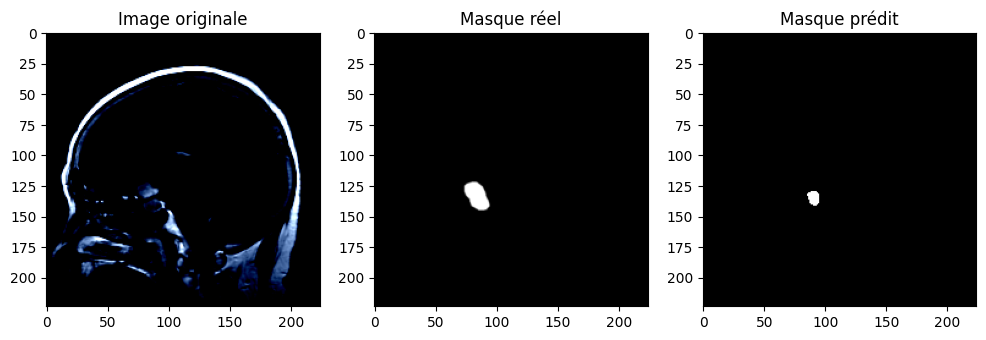

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.4308496].


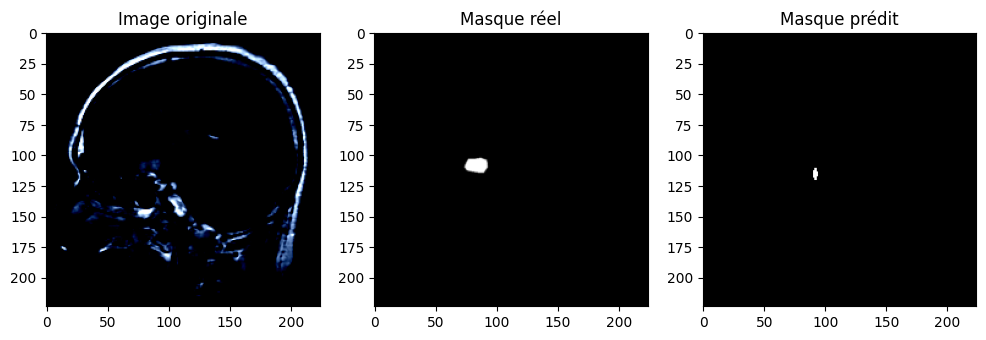

In [12]:
evaluate_and_visualize(model, train_class_loader, train_seg_loader, device)


In [13]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve, auc
import seaborn as sns

def evaluate_model(model, dataloader, device, class_names):
    model.eval()
    y_true, y_pred, y_probs = [], [], []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs, _ = model(images)
            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())

    # Rapport de classification
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Matrice de confusion
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap="Blues", xticks_rotation=45)
    plt.title("Matrice de confusion")
    plt.show()

    # Courbes ROC pour chaque classe
    y_true_bin = np.eye(len(class_names))[y_true]
    for i, name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], np.array(y_probs)[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title("Courbes ROC par classe")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid(True)
    plt.show()


In [14]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image
import cv2
import seaborn as sns

# --- Grad-CAM Helper ---
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook()

    def hook(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate(self, input_tensor, target_class=None):
        self.model.zero_grad()
        output, _ = self.model(input_tensor)
        if target_class is None:
            target_class = torch.argmax(output)
        loss = output[0, target_class]
        loss.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1).squeeze()
        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / cam.max()
        cam = cam.cpu().numpy()
        return cam

# --- Overlay CAM + BBOX ---
def show_cam_with_bbox(input_tensor, cam):
    img = input_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
    img = (img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]))
    img = np.clip(img, 0, 1)
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    heatmap = np.float32(heatmap) / 255
    superimposed_img = heatmap * 0.5 + img * 0.5

    # Bounding box
    thresholded = cam > 0.5
    coords = np.argwhere(thresholded)
    if coords.any():
        y0, x0 = coords.min(axis=0)
        y1, x1 = coords.max(axis=0)
        cv2.rectangle(superimposed_img, (x0, y0), (x1, y1), (0, 255, 0), 2)

    plt.figure(figsize=(6, 6))
    plt.imshow(superimposed_img)
    plt.axis('off')
    plt.title("Grad-CAM + Bounding Box")
    plt.show()

# --- Test-Time Augmentation ---
def predict_with_tta_strong(model, image, device, tta_transforms):
    model.eval()
    image = image.to(device)
    outputs = []
    with torch.no_grad():
        for tta in tta_transforms:
            tta_img = tta(image)
            pred, _ = model(tta_img.unsqueeze(0))
            outputs.append(torch.softmax(pred, dim=1))

    outputs_stack = torch.stack(outputs)
    mean_probs = outputs_stack.mean(dim=0)
    vote_preds = torch.argmax(outputs_stack, dim=2).squeeze().tolist()
    majority_vote = max(set(vote_preds), key=vote_preds.count)
    confidence = mean_probs[0][majority_vote].item()
    return majority_vote, confidence, mean_probs

# --- Barplot des confiances ---
def show_confidence_bar(probs, class_names):
    probs = probs.cpu().numpy().squeeze()
    plt.figure(figsize=(8, 3))
    sns.barplot(x=class_names, y=probs)
    plt.title("Distribution des probabilités")
    plt.ylim([0, 1])
    plt.ylabel("Confiance")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.show()

# --- Pipeline complet d'inférence avec CAM, TTA, Confiance ---
def full_inference_pipeline(image_path, model, device, class_names):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    image = Image.open(image_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)

    # TTA
    tta_transforms = [
        lambda x: x,
        lambda x: torch.flip(x, dims=[2]),
        lambda x: torch.rot90(x, 1, [1, 2]),
        lambda x: torch.rot90(x, 2, [1, 2]),
    ]
    pred_class, confidence, mean_probs = predict_with_tta_strong(model, input_tensor[0], device, tta_transforms)
    print(f"Prediction: {class_names[pred_class]} (confiance = {confidence*100:.2f}%)")

    show_confidence_bar(mean_probs, class_names)

    # Grad-CAM
    cam_generator = GradCAM(model, model.backbone._conv_head)
    cam = cam_generator.generate(input_tensor, target_class=pred_class)
    show_cam_with_bbox(input_tensor, cam)


In [15]:
# Imports requis
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
from torchvision import transforms
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

# Fonction Grad-CAM + Bounding Box

def generate_gradcam_bbox(model, image_tensor, target_class, device):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Features hook
    features = []
    def hook_fn(module, input, output):
        features.append(output)
    hook = model.backbone._conv_head.register_forward_hook(hook_fn)

    outputs, _ = model(image_tensor)
    hook.remove()

    model.zero_grad()
    outputs[0, target_class].backward()
    grads = model.backbone._conv_head.weight.grad
    pooled_grads = torch.mean(grads, dim=[0, 2, 3])
    fmap = features[0][0]
    
    for i in range(len(pooled_grads)):
        fmap[i, :, :] *= pooled_grads[i]

    heatmap = torch.mean(fmap, dim=0).cpu().detach().numpy()
    heatmap = np.maximum(heatmap, 0)
    heatmap /= np.max(heatmap)

    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    img = image_tensor[0].cpu().permute(1, 2, 0).numpy()
    img = (img * 255).astype(np.uint8)

    overlay = cv2.addWeighted(img, 0.6, heatmap_color, 0.4, 0)

    # Bounding box
    thresh = heatmap > 150
    contours, _ = cv2.findContours(thresh.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(overlay, (x, y), (x+w, y+h), (255, 255, 255), 2)

    return overlay

# TTA prediction

def predict_with_tta(model, image_tensor, device):
    tta_transforms = [
        lambda x: x,
        lambda x: torch.flip(x, [1]),
        lambda x: torch.flip(x, [2]),
        lambda x: torch.rot90(x, k=1, dims=[1, 2]),
    ]
    
    model.eval()
    predictions = []
    for t in tta_transforms:
        augmented = t(image_tensor).unsqueeze(0).to(device)
        with torch.no_grad():
            out, _ = model(augmented)
            predictions.append(F.softmax(out, dim=1))

    final_pred = torch.mean(torch.stack(predictions), dim=0)
    confidence, pred_class = torch.max(final_pred, dim=1)
    return pred_class.item(), confidence.item(), final_pred

# Confidence bar plot

def plot_confidence_bar(predictions, class_names):
    probs = predictions.squeeze().cpu().numpy()
    plt.figure(figsize=(8, 4))
    sns.barplot(x=class_names, y=probs)
    plt.title("Class Probabilities")
    plt.ylabel("Confidence")
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.show()

# Test pipeline complet sur une image

def run_inference_example(model, image_path, device, class_names):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image)

    pred_class, confidence, pred_logits = predict_with_tta(model, image_tensor, device)
    print(f"Predicted Class: {class_names[pred_class]} | Confidence: {confidence:.2f}")

    plot_confidence_bar(pred_logits, class_names)

    gradcam_result = generate_gradcam_bbox(model, image_tensor, pred_class, device)
    plt.imshow(gradcam_result)
    plt.title("Grad-CAM with Bounding Box")
    plt.axis('off')
    plt.show()

# Évaluation: Matrice de confusion et classification report

def evaluate_model(model, dataloader, class_names, device):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs, _ = model(images)
            preds = torch.argmax(outputs, dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    print(classification_report(y_true, y_pred, target_names=class_names))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap="Blues")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()

    # ROC Curve (if binary classification)
    if len(class_names) == 2:
        fpr, tpr, _ = roc_curve(y_true, y_pred)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve")
        plt.legend()
        plt.grid()
        plt.show()


In [24]:
# Imports requis
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
from torchvision import transforms
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

# Fonction Grad-CAM + Bounding Box

def generate_gradcam_bbox(model, image_tensor, target_class, device):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Features hook
    features = []
    def hook_fn(module, input, output):
        features.append(output)
    hook = model.backbone._conv_head.register_forward_hook(hook_fn)

    outputs, _ = model(image_tensor)
    hook.remove()

    model.zero_grad()
    outputs[0, target_class].backward()
    grads = model.backbone._conv_head.weight.grad
    pooled_grads = torch.mean(grads, dim=[0, 2, 3])
    fmap = features[0][0]
    
    for i in range(len(pooled_grads)):
        fmap[i, :, :] *= pooled_grads[i]

    heatmap = torch.mean(fmap, dim=0).cpu().detach().numpy()
    heatmap = np.maximum(heatmap, 0)
    heatmap /= np.max(heatmap)

    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    img = image_tensor[0].cpu().permute(1, 2, 0).numpy()
    img = (img * 255).astype(np.uint8)

    overlay = cv2.addWeighted(img, 0.6, heatmap_color, 0.4, 0)

    # Bounding box
    thresh = heatmap > 150
    contours, _ = cv2.findContours(thresh.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(overlay, (x, y), (x+w, y+h), (255, 255, 255), 2)

    return overlay

# TTA prediction

def predict_with_tta(model, image_tensor, device):
    tta_transforms = [
        lambda x: x,
        lambda x: torch.flip(x, [1]),
        lambda x: torch.flip(x, [2]),
        lambda x: torch.rot90(x, k=1, dims=[1, 2]),
    ]
    
    model.eval()
    predictions = []
    for t in tta_transforms:
        augmented = t(image_tensor).unsqueeze(0).to(device)
        with torch.no_grad():
            out, _ = model(augmented)
            predictions.append(F.softmax(out, dim=1))

    final_pred = torch.mean(torch.stack(predictions), dim=0)
    confidence, pred_class = torch.max(final_pred, dim=1)
    return pred_class.item(), confidence.item(), final_pred

# Confidence bar plot

def plot_confidence_bar(predictions, class_names):
    probs = predictions.squeeze().cpu().numpy()
    plt.figure(figsize=(8, 4))
    sns.barplot(x=class_names, y=probs)
    plt.title("Class Probabilities")
    plt.ylabel("Confidence")
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.show()

# Test pipeline complet sur une image

def run_inference_example(model, image_path, device, class_names):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image)

    pred_class, confidence, pred_logits = predict_with_tta(model, image_tensor, device)
    print(f"Predicted Class: {class_names[pred_class]} | Confidence: {confidence:.2f}")

    plot_confidence_bar(pred_logits, class_names)

    gradcam_result = generate_gradcam_bbox(model, image_tensor, pred_class, device)
    plt.imshow(gradcam_result)
    plt.title("Grad-CAM with Bounding Box")
    plt.axis('off')
    plt.show()

# Évaluation: Matrice de confusion et classification report

def evaluate_model(model, dataloader, class_names, device):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs, _ = model(images)
            preds = torch.argmax(outputs, dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    print(classification_report(y_true, y_pred, target_names=class_names))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap="Blues")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()

    # ROC Curve (if binary classification)
    if len(class_names) == 2:
        fpr, tpr, _ = roc_curve(y_true, y_pred)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve")
        plt.legend()
        plt.grid()
        plt.show()


In [16]:
model = MultiTaskModel(num_classes=4)
model.load_state_dict(torch.load("model_multitask.pth", map_location=torch.device("cuda" if torch.cuda.is_available() else "cpu")))
model.eval().to(device)


Loaded pretrained weights for efficientnet-b0


C:\Users\bough\AppData\Local\Temp\ipykernel_20176\3812344892.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("model_multitask.pth", map_

MultiTaskModel(
  (backbone): EfficientNet(
    (_conv_stem): Conv2dStaticSamePadding(
      3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False
      (static_padding): ZeroPad2d((0, 1, 0, 1))
    )
    (_bn0): BatchNorm2d(32, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
    (_blocks): ModuleList(
      (0): MBConvBlock(
        (_depthwise_conv): Conv2dStaticSamePadding(
          32, 32, kernel_size=(3, 3), stride=[1, 1], groups=32, bias=False
          (static_padding): ZeroPad2d((1, 1, 1, 1))
        )
        (_bn1): BatchNorm2d(32, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
        (_se_reduce): Conv2dStaticSamePadding(
          32, 8, kernel_size=(1, 1), stride=(1, 1)
          (static_padding): Identity()
        )
        (_se_expand): Conv2dStaticSamePadding(
          8, 32, kernel_size=(1, 1), stride=(1, 1)
          (static_padding): Identity()
        )
        (_project_conv): Conv2dStaticSamePad

In [27]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
import seaborn as sns
from torchvision import transforms
from PIL import Image
import cv2

#  EVALUATION FUNCTION
def evaluate_model(model, class_loader, seg_loader, device):
    model.eval()
    y_true = []
    y_pred = []
    y_probs = []
    iou_scores = []

    with torch.no_grad():
        for images, labels in class_loader:
            images, labels = images.to(device), labels.to(device)
            outputs, _ = model(images)
            probs = F.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())

        for images, masks in seg_loader:
            images, masks = images.to(device), masks.to(device)
            _, seg_preds = model(images)
            seg_preds = (seg_preds > 0.5).float()

            iou = ((seg_preds * masks).sum((1, 2, 3)) + 1e-6) / ((seg_preds + masks - seg_preds * masks).sum((1, 2, 3)) + 1e-6)
            iou_scores.extend(iou.cpu().numpy())

    #  Metrics
    print("\n--- Classification Report ---")
    print(classification_report(y_true, y_pred))

    print("\n--- Confusion Matrix ---")
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title("Confusion Matrix")
    plt.show()

    #  ROC-AUC
    y_true_onehot = F.one_hot(torch.tensor(y_true), num_classes=len(set(y_true)))
    y_probs = np.array(y_probs)
    roc_auc = roc_auc_score(y_true_onehot, y_probs, average='macro', multi_class='ovo')
    print(f"ROC-AUC: {roc_auc:.4f}")

    #  IOU Score
    print(f"Average IoU (Segmentation): {np.mean(iou_scores):.4f}")


In [46]:
# GRAD-CAM with Heatmap and BBOX
def generate_gradcam_heatmap_bbox(model, image_tensor, class_names):
    model.eval()
    image_tensor = image_tensor.unsqueeze(0).to(next(model.parameters()).device)

    features = []
    def hook(module, input, output):
        features.append(output)

    handle = model.backbone._conv_head.register_forward_hook(hook)
    output, _ = model(image_tensor)
    pred_class = output.argmax(dim=1).item()
    class_idx = pred_class

    grads = torch.autograd.grad(outputs=output[:, class_idx], inputs=features[0],
                                grad_outputs=torch.ones_like(output[:, class_idx]),
                                retain_graph=True)[0]

    pooled_grads = grads.mean(dim=[0, 2, 3])
    feature_map = features[0][0]
    for i in range(len(pooled_grads)):
        feature_map[i] *= pooled_grads[i]

    heatmap = feature_map.mean(dim=0).cpu().detach().numpy()
    heatmap = np.maximum(heatmap, 0)
    heatmap /= np.max(heatmap)
    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap_colored = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    image_np = image_tensor.squeeze().cpu().permute(1, 2, 0).numpy()
    image_np = (image_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]))
    image_np = np.clip(image_np, 0, 1)
    image_np = np.uint8(image_np * 255)

    overlay = cv2.addWeighted(image_np, 0.6, heatmap_colored, 0.4, 0)

    # Bounding box (simple threshold-based)
    gray = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2GRAY)
    thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)[1]
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(overlay, (x, y), (x+w, y+h), (255, 255, 255), 2)

    plt.imshow(overlay)
    plt.title(f"Grad-CAM - Predicted: {class_names[class_idx]}")
    plt.axis("off")
    plt.show()
    handle.remove()


In [60]:
# PREDICTION AVEC TTA
def predict_with_tta(model, image, tta_transforms, class_names):
    device = next(model.parameters()).device
    model.eval()
    probs_list = []

    for t in tta_transforms:
        img_aug = t(image)
        img_tensor = img_aug.unsqueeze(0).to(device)
        with torch.no_grad():
            outputs, _ = model(img_tensor)
            probs = F.softmax(outputs, dim=1).detach().cpu().numpy()  
            probs_list.append(probs)

    probs_avg = np.mean(probs_list, axis=0)[0]
    pred_idx = np.argmax(probs_avg)
    print(f"Predicted Class with TTA: {class_names[pred_idx]} | Confidence: {probs_avg[pred_idx]:.4f}")


In [41]:
#  CONFIDENCE ESTIMATION
def predict_with_confidence(model, img_tensor, class_names):
    model.eval()
    with torch.no_grad():
        img_tensor = img_tensor.unsqueeze(0).to(next(model.parameters()).device)
        outputs, _ = model(img_tensor)
        probs = F.softmax(outputs, dim=1).squeeze()
        pred_idx = torch.argmax(probs).item()

    print(f"Predicted: {class_names[pred_idx]} | Confidence: {probs[pred_idx]:.4f}")
    plt.bar(range(len(probs)), probs.cpu().numpy())
    plt.xticks(ticks=range(len(class_names)), labels=class_names, rotation=45)
    plt.title("Confidence Distribution")
    plt.show()


In [42]:
#  ROC CURVE FUNCTION 
def plot_roc_auc(model, data_loader, device, num_classes):
    model.eval()
    y_true = []
    y_probs = []
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            outputs, _ = model(inputs)
            probs = F.softmax(outputs, dim=1).cpu().numpy()
            y_probs.extend(probs)
            y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_probs = np.array(y_probs)
    y_true_1hot = np.eye(num_classes)[y_true]

    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(y_true_1hot[:, i], y_probs[:, i])
        plt.plot(fpr, tpr, label=f"Class {i} AUC = {auc(fpr, tpr):.2f}")

    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend()
    plt.grid(True)
    plt.show()


In [43]:
#  PLOT CONFIDENCE DISTRIBUTION (per class)
def plot_confidence_distribution(probabilities):
    probabilities = np.array(probabilities)
    plt.figure(figsize=(8, 4))
    for i in range(probabilities.shape[1]):
        sns.kdeplot(probabilities[:, i], label=f"Class {i}")
    plt.title("Confidence Distribution per Class")
    plt.xlabel("Confidence")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True)
    plt.show()



--- Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       826
           1       1.00      1.00      1.00       822
           2       1.00      1.00      1.00       395
           3       1.00      1.00      1.00       827

    accuracy                           1.00      2870
   macro avg       1.00      1.00      1.00      2870
weighted avg       1.00      1.00      1.00      2870


--- Confusion Matrix ---


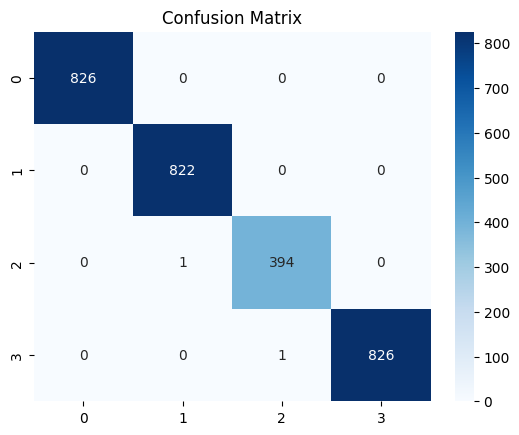

ROC-AUC: 0.9993
Average IoU (Segmentation): 0.5151


In [33]:
evaluate_model(model, train_class_loader, train_seg_loader, device)



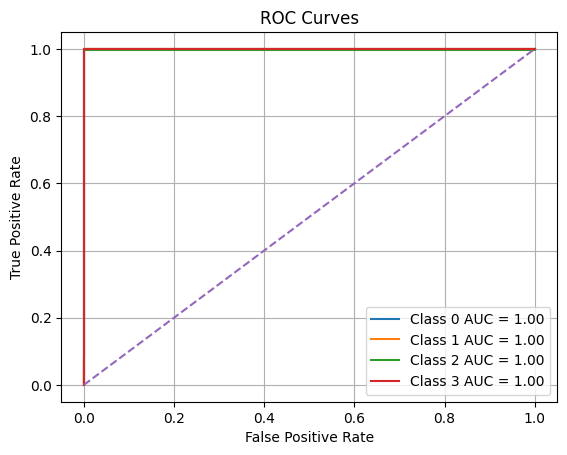

In [37]:
plot_roc_auc(model, train_class_loader, device, num_classes=4)


In [52]:
from PIL import Image
from torchvision import transforms

# Remplace ce chemin par une image réelle du dossier de test
img_path = "Brain-Tumor-Classification-DataSet-master/Testing/glioma_tumor/image(34).jpg"

# Prétraitement comme pendant l’entraînement
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

image = Image.open(img_path).convert("RGB")
image_tensor = transform(image).to(device)


In [83]:
class_names = ["glioma_tumor", "meningioma_tumor",  "no_tumor","pituitary_tumor"]



--- Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       826
           1       1.00      1.00      1.00       822
           2       1.00      1.00      1.00       395
           3       1.00      1.00      1.00       827

    accuracy                           1.00      2870
   macro avg       1.00      1.00      1.00      2870
weighted avg       1.00      1.00      1.00      2870


--- Confusion Matrix ---


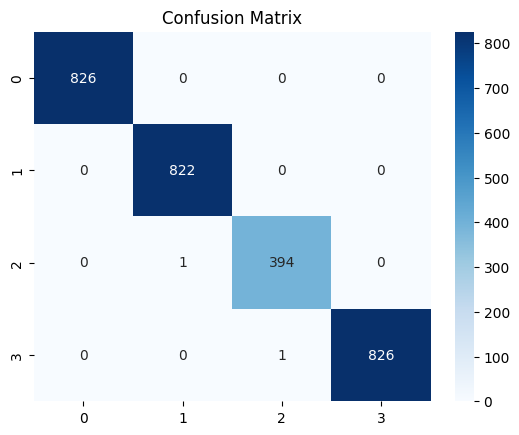

ROC-AUC: 0.9993
Average IoU (Segmentation): 0.5151


In [54]:
evaluate_model(model, train_class_loader, train_seg_loader, device)


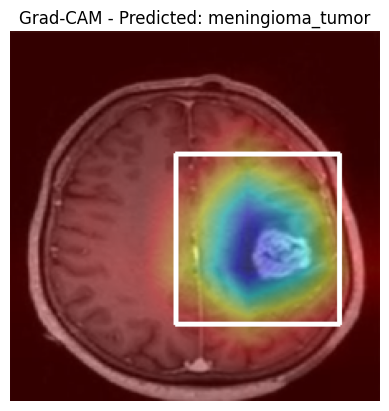

In [55]:
generate_gradcam_heatmap_bbox(model, image_tensor, class_names)


In [61]:
tta_transforms = [
    lambda img: transform(img),
    lambda img: transform(transforms.functional.hflip(img)),
    lambda img: transform(transforms.functional.vflip(img)),
    lambda img: transform(transforms.functional.rotate(img, 15)),
]

predict_with_tta(model, image, tta_transforms, class_names)


Predicted Class with TTA: meningioma_tumor | Confidence: 0.9974


Predicted: meningioma_tumor | Confidence: 0.9971


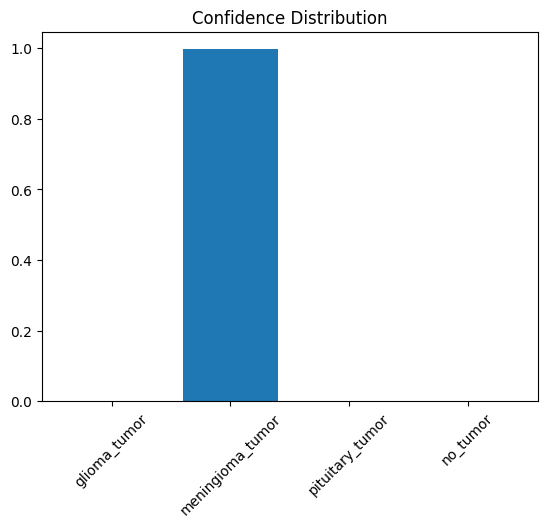

In [57]:
predict_with_confidence(model, image_tensor, class_names)


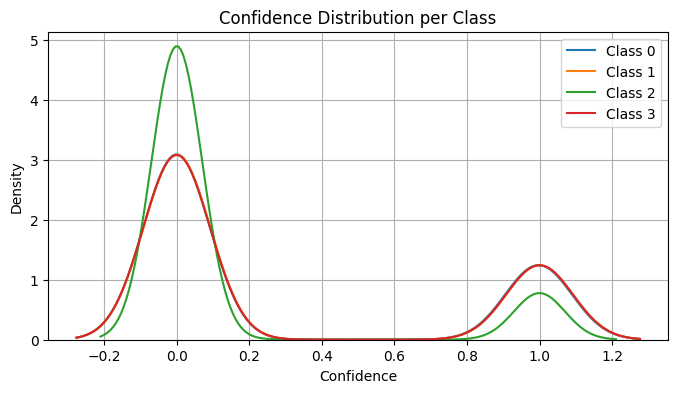

In [58]:
y_probs = []

model.eval()
with torch.no_grad():
    for inputs, _ in train_class_loader:
        inputs = inputs.to(device)
        outputs, _ = model(inputs)
        probs = F.softmax(outputs, dim=1)
        y_probs.extend(probs.cpu().numpy())

plot_confidence_distribution(np.array(y_probs))


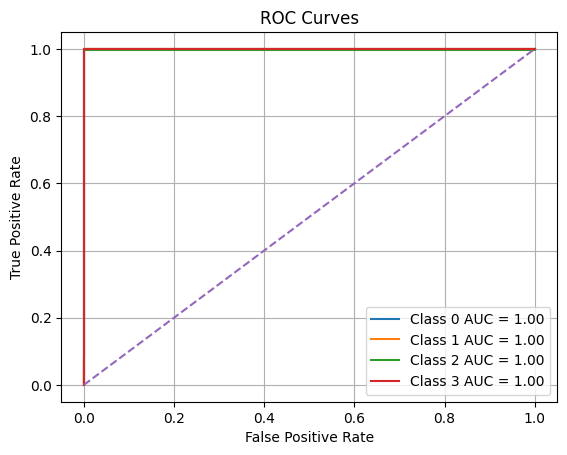

In [59]:
plot_roc_auc(model, train_class_loader, device, num_classes=4)


In [67]:
from PIL import Image
from torchvision import transforms

# Remplace ce chemin par une image réelle du dossier de test
img_path = "Brain-Tumor-Classification-DataSet-master/Testing/pituitary_tumor/image(57).jpg"

# Prétraitement comme pendant l’entraînement
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

image = Image.open(img_path).convert("RGB")
image_tensor = transform(image).to(device)


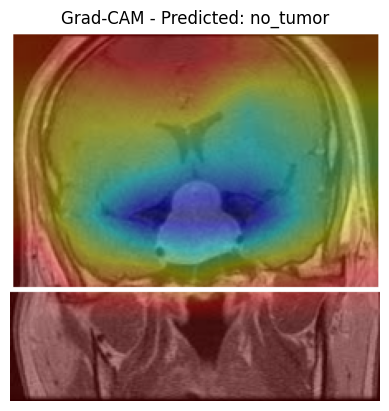

In [68]:
generate_gradcam_heatmap_bbox(model, image_tensor, class_names)


In [69]:
tta_transforms = [
    lambda img: transform(img),
    lambda img: transform(transforms.functional.hflip(img)),
    lambda img: transform(transforms.functional.vflip(img)),
    lambda img: transform(transforms.functional.rotate(img, 15)),
]

predict_with_tta(model, image, tta_transforms, class_names)


Predicted Class with TTA: no_tumor | Confidence: 0.7213


Predicted: no_tumor | Confidence: 0.9985


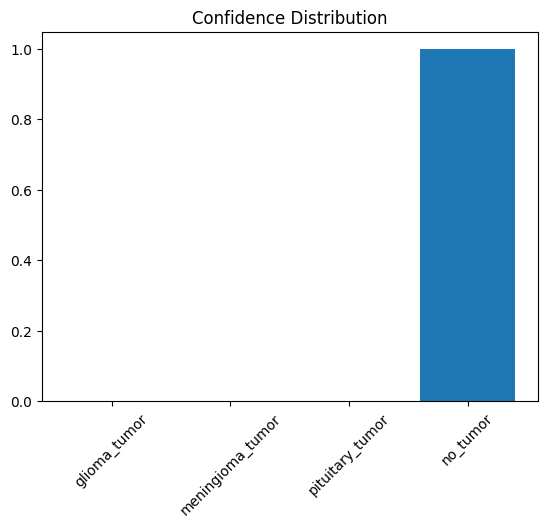

In [70]:
predict_with_confidence(model, image_tensor, class_names)


In [71]:
from PIL import Image
from torchvision import transforms

# Remplace ce chemin par une image réelle du dossier de test
img_path = "Brain-Tumor-Classification-DataSet-master/Testing/pituitary_tumor/image(19).jpg"

# Prétraitement comme pendant l’entraînement
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

image = Image.open(img_path).convert("RGB")
image_tensor = transform(image).to(device)


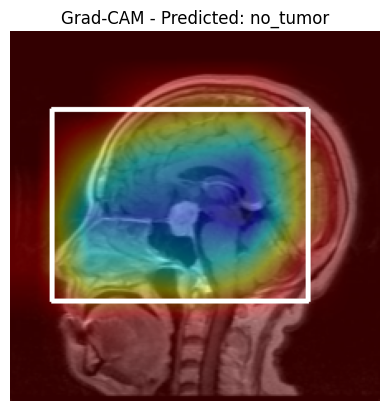

In [72]:
generate_gradcam_heatmap_bbox(model, image_tensor, class_names)


In [73]:
tta_transforms = [
    lambda img: transform(img),
    lambda img: transform(transforms.functional.hflip(img)),
    lambda img: transform(transforms.functional.vflip(img)),
    lambda img: transform(transforms.functional.rotate(img, 15)),
]

predict_with_tta(model, image, tta_transforms, class_names)


Predicted Class with TTA: no_tumor | Confidence: 0.5970


Predicted: no_tumor | Confidence: 0.9905


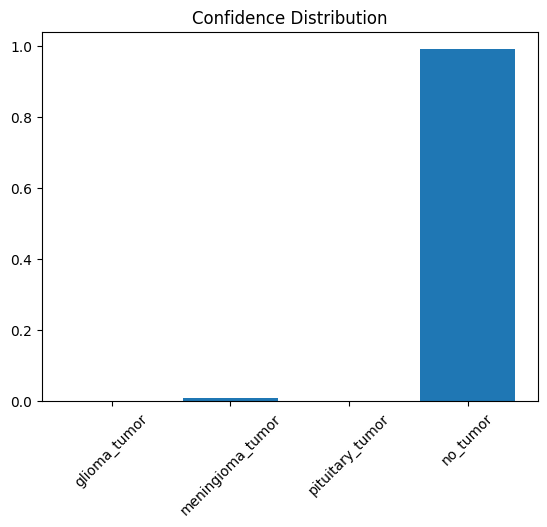

In [74]:
predict_with_confidence(model, image_tensor, class_names)


In [75]:
from PIL import Image
from torchvision import transforms

# Remplace ce chemin par une image réelle du dossier de test
img_path = "Brain-Tumor-Classification-DataSet-master/Testing/no_tumor/image(33).jpg"

# Prétraitement comme pendant l’entraînement
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

image = Image.open(img_path).convert("RGB")
image_tensor = transform(image).to(device)


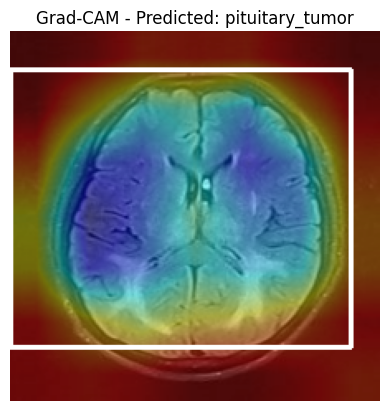

In [76]:
generate_gradcam_heatmap_bbox(model, image_tensor, class_names)


In [77]:
tta_transforms = [
    lambda img: transform(img),
    lambda img: transform(transforms.functional.hflip(img)),
    lambda img: transform(transforms.functional.vflip(img)),
    lambda img: transform(transforms.functional.rotate(img, 15)),
]

predict_with_tta(model, image, tta_transforms, class_names)


Predicted Class with TTA: pituitary_tumor | Confidence: 1.0000


Predicted: pituitary_tumor | Confidence: 0.9999


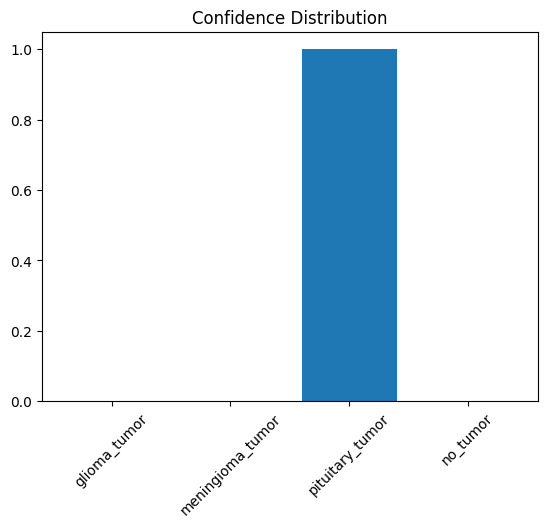

In [78]:
predict_with_confidence(model, image_tensor, class_names)


In [79]:
from PIL import Image
from torchvision import transforms

# Remplace ce chemin par une image réelle du dossier de test
img_path = "Brain-Tumor-Classification-DataSet-master/Testing/pituitary_tumor/image.jpg"

# Prétraitement comme pendant l’entraînement
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

image = Image.open(img_path).convert("RGB")
image_tensor = transform(image).to(device)


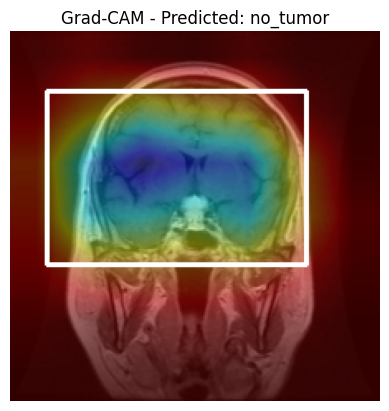

In [80]:
generate_gradcam_heatmap_bbox(model, image_tensor, class_names)


In [84]:
from PIL import Image
from torchvision import transforms

# Remplace ce chemin par une image réelle du dossier de test
img_path = "Brain-Tumor-Classification-DataSet-master/Testing/glioma_tumor/image(54).jpg"

# Prétraitement comme pendant l’entraînement
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

image = Image.open(img_path).convert("RGB")
image_tensor = transform(image).to(device)


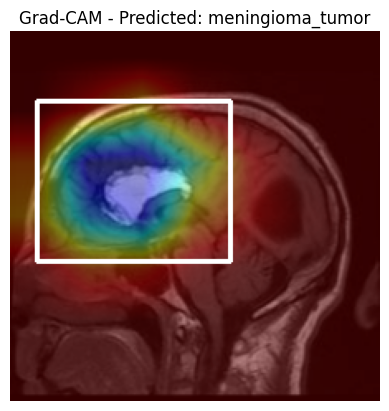

In [85]:
generate_gradcam_heatmap_bbox(model, image_tensor, class_names)
